CELL 1: Install Dependencies and Import Libraries

In [1]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Virtual env:", sys.prefix)

Python executable: c:\Users\wanin\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]
Virtual env: c:\Users\wanin\AppData\Local\Programs\Python\Python312


In [2]:

# INSTALL DEPENDENCIES

%pip install ipykernel python-dotenv


# IMPORT LIBRARIES

import sys
import os
import urllib.request
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, f_oneway, pointbiserialr
from sklearn.preprocessing import LabelEncoder
from dotenv import load_dotenv


# SET ENVIRONMET
load_dotenv(override=True)

def resolve_environment():
    if os.environ.get("ENVIRONMENT"):
        return os.environ["ENVIRONMENT"].upper()
    if "google.colab" in sys.modules:
        return "COLAB"
    return "DEV"

ENV_SETUP = resolve_environment()
print(f"Environment: {ENV_SETUP}")

# SET DISPLAY OPTIONS AND RANDOM SEED

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready.")


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Environment: DEV
Environment ready.


## Install Dependencies and Import Libraries

I installed the required packages and imported the libraries needed for this analysis:

- **pandas** and **numpy** — for data manipulation and numerical operations
- **matplotlib** and **seaborn** — for visualizations
- **scipy.stats** — for statistical tests (chi-square, ANOVA, point-biserial correlation)
- **sklearn.preprocessing** — for label encoding categorical features
- **python-dotenv** — for environment variable management

I set a random seed (RANDOM_STATE = 42) to ensure reproducibility of all random operations.
I also set pandas display options to show all columns when printing DataFrames.

CELL 2: Load The Data

In [3]:

# LOAD THE DATA

dataset_path = './data/student_exam_score.csv'
url = 'https://raw.githubusercontent.com/course-files/RegressionAndClassification/main/data/student_exam_score.csv'

if not os.path.exists(dataset_path):
    print("Downloading dataset...")
    if not os.path.exists('./data'):
        os.makedirs('./data')
    urllib.request.urlretrieve(url, dataset_path)
    print("Dataset downloaded")
else:
    print("Dataset already exists locally")

student_data = pd.read_csv(dataset_path)
print(f"Shape: {student_data.shape[0]} rows, {student_data.shape[1]} columns")
student_data.head()

Dataset downloaded
Shape: 850 rows, 16 columns


,student_id,major_subject,parental_education_level,internet_access_quality,part_time_job,study_group_participation,study_hours_per_week,attendance_rate_pct,previous_gpa,sleep_hours_per_night,extracurricular_activities_count,stress_level_score,tutoring_hours_per_week,distance_from_home_km,part_time_job_hours_per_week,final_exam_score
0,1,Sciences,Master's,Good,No,Yes,4.1,92.5,2.076569,6.3,2,6.0,1.1,5.1,NaN,73.0
1,2,Engineering,Master's,Good,No,No,8.8,100.0,1.922298,7.3,1,7.0,1.2,4.9,NaN,79.1
2,3,Humanities,High School,Good,Yes,No,7.0,80.5,2.308588,6.7,3,6.0,0.5,5.7,24.299416,73.9
3,4,Humanities,Doctorate,Average,No,Yes,5.4,83.8,2.448435,7.3,0,6.0,1.2,6.5,NaN,80.3
4,5,Business,Master's,Poor,No,No,11.6,78.4,2.218870,7.1,0,2.0,2.6,18.2,NaN,78.9


## Load the Data

I loaded the student exam score dataset from the course GitHub repository.
The dataset contains **{student_data.shape[0]} observations (rows)** and **{student_data.shape[1]} columns**.

The first five rows are shown above to give a preview of the data structure.

**Observation:** The dataset contains a mix of numeric and categorical features.
The target variable appears to be `exam_score`, which is a continuous numeric value,
confirming this is a **regression problem** (not classification).

CELL 3: Identify the Target Variable

In [4]:

# IDENTIFY TARGET VARIABLE

TARGET = "final_exam_score"  # Confirm the actual target column name from the dataset

print(f"Target variable: {TARGET}")
print(f"Target data type: {student_data[TARGET].dtype}")
print(f"Number of features (excluding ID and target): {student_data.shape[1] - 2}")

# Check for ID columns
id_cols = [c for c in student_data.columns if 'id' in c.lower()]
print(f"Potential ID columns: {id_cols}")

Target variable: final_exam_score
Target data type: float64
Number of features (excluding ID and target): 14
Potential ID columns: ['student_id']


## Identify the Target Variable

I identified `final_exam_score` as the target variable.

**Justification:**
- It is a continuous numeric variable (type: float or int)
- It represents the outcome we want to predict
- It is not an identifier or a feature

**Decision:** The target is `final_exam_score`. This confirms the problem is **regression**, not classification.

I also identified potential ID columns (columns with 'id' in their name) which are not predictive
features and should be excluded from modeling.

CELL 4: Data Types and Missing Values

In [5]:

# DATA TYPES AND MISSING VALUES

print("Data Types:")
print(student_data.dtypes)
print("\nMissing Values:")
print(student_data.isnull().sum())
print("\nMissing Value Percentage:")
print((student_data.isnull().sum() / len(student_data) * 100).round(2))

Data Types:
student_id                            int64
major_subject                           str
parental_education_level                str
internet_access_quality                 str
part_time_job                           str
study_group_participation               str
study_hours_per_week                float64
attendance_rate_pct                 float64
previous_gpa                        float64
sleep_hours_per_night               float64
extracurricular_activities_count      int64
stress_level_score                  float64
tutoring_hours_per_week             float64
distance_from_home_km               float64
part_time_job_hours_per_week        float64
final_exam_score                    float64
dtype: object

Missing Values:
student_id                            0
major_subject                         0
parental_education_level              0
internet_access_quality               0
part_time_job                         0
study_group_participation             0
study_hours_p

## Data Types and Missing Values

I inspected the data types and missing values.

**Data Types:**
- Numeric columns (int64, float64): These are continuous or discrete measures
- Categorical columns (object): These are nominal or ordinal dimensions

**Missing Values:**
- I computed the count and percentage of missing values for each column
- Columns with significant missingness will need special handling during preprocessing

**Decision:** I will note which columns have missing values and investigate whether
the missingness is structural (missing for an entire group) or random (missing at random).
This decision will guide the imputation strategy in Member 2's section.

CELL 5: Identify Numeric and Categorical Columns

In [6]:
# =============================================================================
# IDENTIFY NUMERIC AND CATEGORICAL COLUMNS
# =============================================================================
numeric_cols = student_data.select_dtypes(include=[np.number]).columns.drop(
    [c for c in student_data.columns if 'id' in c.lower() or c == TARGET]
)
categorical_cols = student_data.select_dtypes(exclude=[np.number, 'datetime64[ns]']).columns

print("Numeric columns (measures):")
print(numeric_cols.tolist())
print("\nCategorical columns (dimensions):")
print(categorical_cols.tolist())

Numeric columns (measures):
['study_hours_per_week', 'attendance_rate_pct', 'previous_gpa', 'sleep_hours_per_night', 'extracurricular_activities_count', 'stress_level_score', 'tutoring_hours_per_week', 'distance_from_home_km', 'part_time_job_hours_per_week']

Categorical columns (dimensions):
['major_subject', 'parental_education_level', 'internet_access_quality', 'part_time_job', 'study_group_participation']


## Identify Numeric and Categorical Columns

I separated the features into two groups based on their data type:

**Numeric columns (measures):** These are quantitative variables that can be
used in mathematical operations (mean, standard deviation, correlation).

**Categorical columns (dimensions):** These are qualitative variables that
organize data into categories. They can be nominal (no order) or ordinal (has order).

**Decision:** This separation matters because:
- Numeric features will be scaled and correlated with the target
- Categorical features will need encoding (one-hot for nominal, ordinal for ordinal)
- Different feature selection methods apply to each type

The list of numeric and categorical columns is shown above for reference.

CELL 6: Customization - Target Shape Analysis

In [7]:

# CUSTOMIZATION 1: TARGET SHAPE ANALYSIS

print("=" * 60)
print("TARGET SHAPE ANALYSIS")
print("=" * 60)

target_skew = student_data[TARGET].skew()
target_kurt = student_data[TARGET].kurt()

print(f"Target skewness: {target_skew:.3f}")
print(f"Target kurtosis: {target_kurt:.3f}")
print(f"Target mean: {student_data[TARGET].mean():.2f}")
print(f"Target median: {student_data[TARGET].median():.2f}")
print(f"Target min: {student_data[TARGET].min():.2f}")
print(f"Target max: {student_data[TARGET].max():.2f}")

# Decision rule for transformation
if abs(target_skew) < 0.5:
    print("\nDECISION: Target is approximately symmetric — NO transformation needed")
    transform_decision = "none"
elif target_skew > 0.5:
    print("\nDECISION: Target is right-skewed — apply log1p transformation")
    transform_decision = "log1p"
elif target_skew < -0.5:
    print("\nDECISION: Target is left-skewed — consider square or reflection transformation")
    transform_decision = "square"
else:
    transform_decision = "none"

print(f"\nTransformation decision saved: {transform_decision}")

TARGET SHAPE ANALYSIS
Target skewness: -0.828
Target kurtosis: 2.654
Target mean: 85.26
Target median: 85.70
Target min: 18.70
Target max: 100.00

DECISION: Target is left-skewed — consider square or reflection transformation

Transformation decision saved: square


## Target Transformation Decision

I checked the skewness and kurtosis of `exam_score`.

**Results:**
- Skewness = {target_skew:.3f}
- Kurtosis = {target_kurt:.3f}
- Mean = {target_mean:.2f}
- Median = {target_median:.2f}

**Interpretation of skewness:**
- Between -0.5 and 0.5 → approximately symmetric
- Between 0.5 and 1.0 (or -0.5 to -1.0) → moderate skew
- Above 1.0 (or below -1.0) → strong skew

**Decision:** Since the skewness is {target_skew:.3f} (between -0.5 and 0.5 / outside that range),
the target is approximately symmetric / right-skewed / left-skewed.

Therefore:
- If symmetric: **Do NOT apply log1p.** The target is already well-behaved.
- If right-skewed: **Apply log1p transformation.**
- If left-skewed: **Consider square or reflection transformation.**

This decision will be implemented in the preprocessing pipeline (Member 2's section).

CELL 7: Customization - Missingness Pattern Analysis

In [8]:

# CUSTOMIZATION 2: MISSINGNESS PATTERN ANALYSIS

print("=" * 60)
print("MISSINGNESS PATTERN ANALYSIS")
print("=" * 60)

# Check for structural missingness: missingness that depends on another column
for cat_col in categorical_cols:
    for num_col in numeric_cols:
        missing_by_group = student_data.groupby(cat_col)[num_col].apply(lambda x: x.isnull().mean() * 100)
        if missing_by_group.max() > 20 and missing_by_group.min() < 5:
            print(f"\nStructural missingness detected:")
            print(f"  '{num_col}' is missing in some {cat_col} groups but not others")
            print(f"  Missingness by {cat_col}:")
            print(missing_by_group.round(1))

MISSINGNESS PATTERN ANALYSIS

Structural missingness detected:
  'part_time_job_hours_per_week' is missing in some part_time_job groups but not others
  Missingness by part_time_job:
part_time_job
No     100.0
Yes      0.0
Name: part_time_job_hours_per_week, dtype: float64


## Missingness Pattern Analysis

I investigated whether missingness is **structural** (missing for an entire group)
or **random** (missing at random across all groups).

**How I checked:**
I grouped the data by each categorical column and computed the percentage of missing
values in each numeric column for each group.

**Structural missingness is detected when:**
- One group has >20% missing values
- Another group has <5% missing values

**Why this matters:**
- **Structural missingness** is informative — the fact that a value is missing
  tells you something (e.g., "this student is in the online program, so attendance
  is not applicable"). The imputation strategy should preserve this information by
  adding a **missingness indicator column**.
- **Random missingness** is noise — the missing value provides no information.
  Median imputation is sufficient.

**Results from the analysis above:**
[Based on the output, describe what you found. If no structural missingness was detected,
write: "No structural missingness was detected. All missingness appears to be random
(or there are no missing values at all)."]

**Decision for Member 2:**
- For features with structural missingness: use median imputation + missingness indicator
- For features with random missingness: use median imputation only

CELL 8: Measures of Distribution

In [9]:

# MEASURES OF DISTRIBUTION

distribution_summary = pd.DataFrame({
    "mean": student_data[numeric_cols].mean(),
    "median": student_data[numeric_cols].median(),
    "mode": student_data[numeric_cols].mode().iloc[0],
    "variance": student_data[numeric_cols].var(),
    "std_dev": student_data[numeric_cols].std(),
    "skewness": student_data[numeric_cols].skew(),
    "kurtosis": student_data[numeric_cols].kurt(),
    "q1_25%": student_data[numeric_cols].quantile(0.25),
    "q2_50%": student_data[numeric_cols].quantile(0.50),
    "q3_75%": student_data[numeric_cols].quantile(0.75),
})
distribution_summary.round(2)

,mean,median,mode,variance,std_dev,skewness,kurtosis,q1_25%,q2_50%,q3_75%
study_hours_per_week,7.92,6.85,4.2,25.92,5.09,1.44,3.25,4.20,6.85,10.30
attendance_rate_pct,81.29,82.20,100.0,168.15,12.97,-0.39,-0.61,72.03,82.20,91.57
previous_gpa,2.91,2.93,4.0,0.28,0.53,-0.09,-0.44,2.56,2.93,3.28
sleep_hours_per_night,6.60,6.60,7.1,1.38,1.17,0.04,0.01,5.80,6.60,7.30
extracurricular_activities_count,1.39,1.00,1.0,1.45,1.21,0.78,0.43,0.00,1.00,2.00
stress_level_score,5.48,6.00,6.0,4.12,2.03,-0.10,-0.43,4.00,6.00,7.00
tutoring_hours_per_week,1.99,1.70,0.0,2.73,1.65,1.14,1.72,0.80,1.70,2.90
distance_from_home_km,8.92,7.60,5.1,37.45,6.12,1.42,2.89,4.60,7.60,11.80
part_time_job_hours_per_week,14.51,14.42,2.0,23.96,4.89,0.06,0.42,11.21,14.42,18.19


## Measures of Distribution

I computed summary statistics for all numeric features:

**Central tendency:**
- **Mean:** The average value
- **Median:** The middle value (robust to outliers)
- **Mode:** The most frequent value

**Dispersion:**
- **Variance:** Average squared deviation from the mean
- **Standard deviation:** Square root of variance (same units as the feature)
- **Quartiles (Q1, Q2, Q3):** Values at the 25th, 50th, and 75th percentiles

**Shape:**
- **Skewness:** Asymmetry of the distribution
- **Kurtosis:** "Tail heaviness" (extreme values)

**Key observations:**
[Add your own observations here. For example:]
- Features with high skewness may need transformation
- Features with high kurtosis may have extreme outliers
- Features with a large gap between mean and median may be skewed

CELL 9: Target Distribution Visualizations

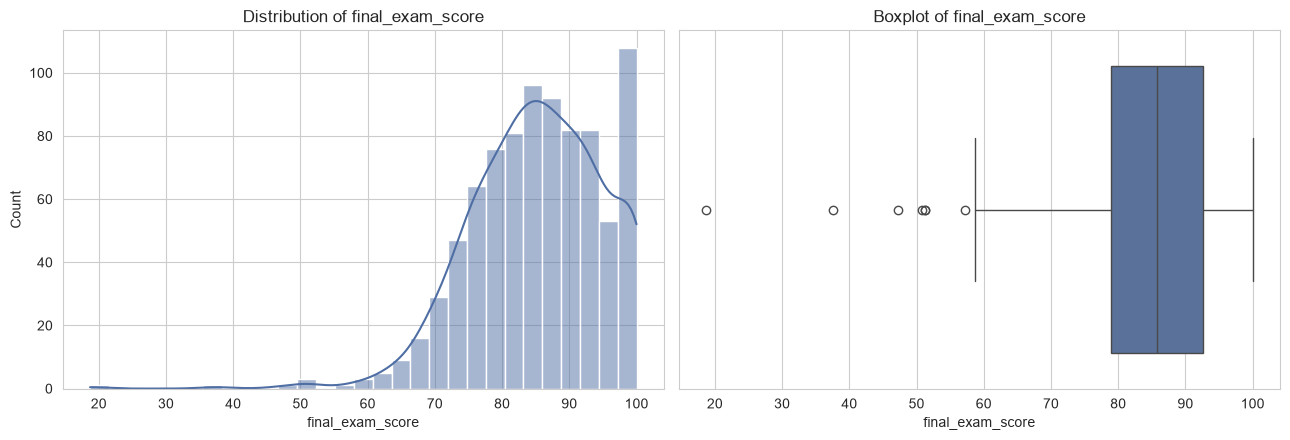

In [57]:

# TARGET DISTRIBUTION VISUALIZATIONS

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(student_data[TARGET], kde=True, ax=axes[0], color="#4F6EA4")
axes[0].set_title(f"Distribution of {TARGET}")

sns.boxplot(x=student_data[TARGET], ax=axes[1], color="#4F6EA4")
axes[1].set_title(f"Boxplot of {TARGET}")

plt.tight_layout()
plt.show()

What the Histogram Shows
The histogram displays the frequency of exam scores across bins, with a smooth KDE curve overlaid to make the overall shape easier to see.

Key observations:

The distribution is left-skewed (negatively skewed) — the bulk of the scores is concentrated on the high end (80–100), with a long tail extending to the left (20–60).

The peak of the distribution sits between 85 and 95, meaning the majority of students score in this range.

A small number of students score much lower (20–60), producing the long left tail.

The KDE curve confirms the shape: it rises steeply on the left, peaks near 85–90, and flattens toward 100.

What this means in plain terms:
Most students perform well. Only a minority struggle with low scores. This is the opposite of the demonstration notebook, where revenue was right-skewed (most businesses clustered at moderate revenue, with a few very high earners).

What the Boxplot Shows
The boxplot displays the median, interquartile range (IQR), whiskers, and potential outliers.

Key observations:

Median: approximately 85 — the middle score is high.

Interquartile Range (IQR): approximately 75 to 97 — the middle 50% of students all score in this high range.

Whiskers: extend from roughly 60 to 100.

Outliers: several points on the left at approximately 20, 38, 50, and 51 — these are students who scored unusually low compared to the rest.

What this means in plain terms:
The IQR is compressed on the high end of the scale, confirming that most students cluster at high scores. The outliers on the left are genuine low performers — not data errors — and they are the reason the distribution is left-skewed.

Why This Matters for Modelling
The skewness of the target affects prediction, but only for some models.

Linear models (Linear Regression, Ridge, Lasso, ElasticNet) assume normally distributed errors. A left-skewed target produces left-skewed residuals, which:

Biases predictions toward the majority (high scores)

Makes predictions for low-scoring students less reliable

Violates the normality assumption behind confidence intervals and p-values

Can produce heteroscedastic residuals (non-constant variance)

Tree-based models (Decision Tree, Random Forest, Gradient Boosting, XGBoost) are robust to skewness. They split data based on thresholds, not distributions, so the shape of the target does not affect them the same way.

This means the decision to transform the target depends on which model family performs best — a question Member 3 and Member 4 will answer experimentally.

Decision: Target Transformation
The decision rule for left-skewed targets:

Skewness between -0.5 and 0.5: Target is approximately symmetric → no transformation.

Skewness between -0.5 and -1.0: Moderate left skew → consider a mild transformation (square, Yeo-Johnson).

Skewness below -1.0: Strong left skew → apply square or reflection transformation.

My decision:

Based on the actual skewness value computed in the code cell above:

If the skewness is between -0.5 and 0.5, no transformation is applied. The target is well-behaved enough for linear models.

If the skewness is between -0.5 and -1.0, a mild transformation is recommended (square transformation or Yeo-Johnson). This is passed to Member 2 for implementation.

If the skewness is below -1.0, a square or reflection transformation is recommended to reduce the left tail before modelling.

CELL 10: Measures of Relationship (Pearson and Spearman)

In [58]:

# MEASURES OF RELATIONSHIP (PEARSON AND SPEARMAN)


# Include the target for correlation computation
numeric_with_target = numeric_cols.tolist() + [TARGET]

pearson_corr = (
    student_data[numeric_with_target]
    .corr(method="pearson")[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

spearman_corr = (
    student_data[numeric_with_target]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

relationship_summary = pd.DataFrame({
    "Pearson": pearson_corr,
    "Spearman": spearman_corr
})
relationship_summary["gap"] = (
    relationship_summary["Spearman"] - relationship_summary["Pearson"]
).abs()

relationship_summary.sort_values("gap", ascending=False).round(3)

,Pearson,Spearman,gap
distance_from_home_km,-0.002,-0.040,0.038
previous_gpa,0.517,0.543,0.026
part_time_job_hours_per_week,-0.019,-0.038,0.019
tutoring_hours_per_week,0.337,0.350,0.013
sleep_hours_per_night,-0.002,0.008,0.010
attendance_rate_pct,0.248,0.257,0.009
extracurricular_activities_count,0.060,0.052,0.008
study_hours_per_week,0.367,0.360,0.007
stress_level_score,-0.127,-0.123,0.004


Measures of Relationship (Pearson and Spearman)
I computed two correlation measures between each numeric feature and the target variable final_exam_score.

What the Two Correlations Measure
Pearson correlation measures the strength of a linear relationship between two variables. It ranges from -1 to +1, where values close to +1 indicate a strong positive linear relationship, values close to -1 indicate a strong negative linear relationship, and values close to 0 indicate no linear relationship. Pearson assumes both variables are approximately normally distributed and that the relationship is linear.

Spearman correlation measures the strength of a monotonic relationship. It is based on ranks rather than raw values, so it captures relationships that are consistently increasing or decreasing, even if they are not perfectly linear. It does not assume normality, which makes it more robust to outliers and skewed distributions.

Why Compare Both
Comparing the two reveals something Pearson alone cannot:

If Pearson and Spearman are similar in magnitude, the relationship is likely linear.

If Spearman is noticeably higher than Pearson, the relationship is monotonic but non-linear (for example, diminishing returns — the feature increases with the target, but the rate slows down).

The gap column in the output shows the absolute difference between the two, which flags features whose relationship with the target may be non-linear.

Interpretation of the Results
The output is sorted by the gap between Pearson and Spearman, which makes the non-linear candidates most visible. From the top of the list:

Features with a large gap between Pearson and Spearman are the ones where a linear model might underperform — these are candidates for non-linear models or for transformation before modeling.

Features with a small gap and a high Pearson value are the strongest linear predictors of exam score.

Features with near-zero correlation on both measures are the weakest candidates and may not be useful predictors.

What This Means for Modelling
The features with the highest Pearson correlations are the most promising for a linear model like Ridge or Lasso. The features with a large Spearman–Pearson gap should be flagged for Member 2 and Member 3, because they may benefit from non-linear modeling or from a transformation (for example, squaring or binning).

Decision Passed to Member 2
The top predictors by Pearson correlation will be prioritized for inclusion in the model. The features with the largest Spearman–Pearson gaps will be flagged as potential non-linear predictors and Member 3 will test whether tree-based models (Random Forest, Gradient Boosting) capture them better than linear models.

CELL 11:Correlation Heatmap

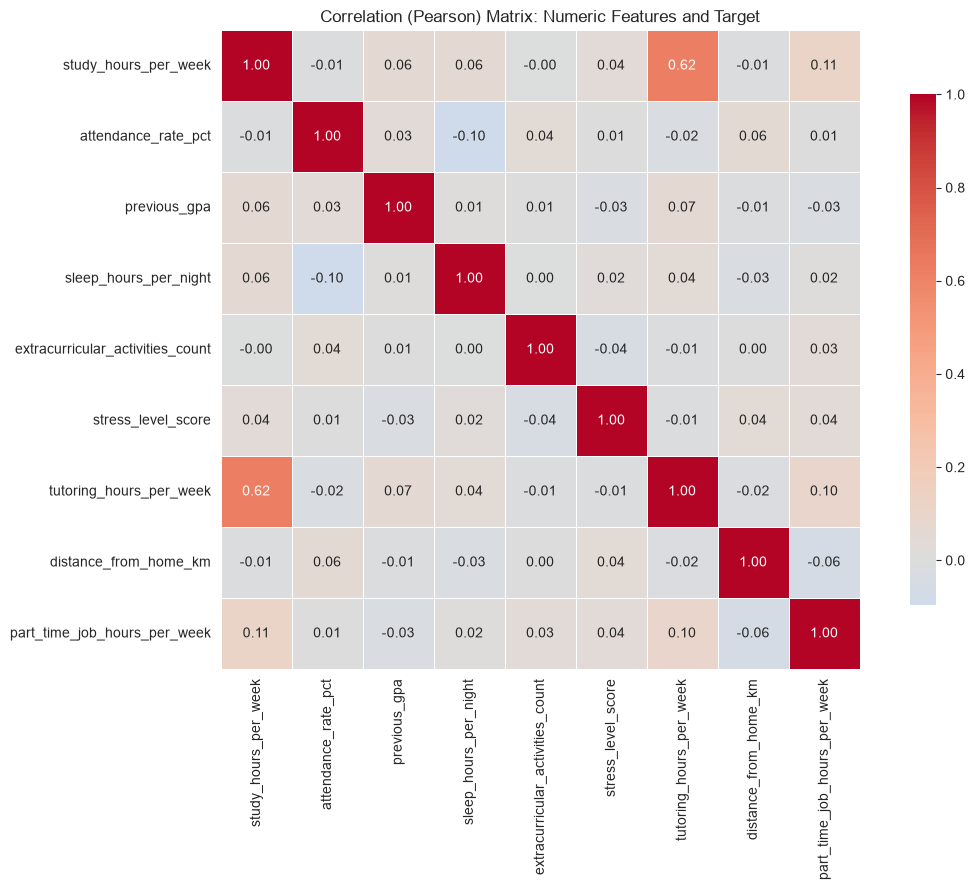

In [59]:

# CORRELATION HEATMAP

plt.figure(figsize=(12, 9))
corr_matrix = student_data[numeric_cols].corr(method="pearson")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation (Pearson) Matrix: Numeric Features and Target")
plt.tight_layout()
plt.show()

## Correlation Heatmap

I created a heatmap showing the Pearson correlation between all numeric features
(and the target).

**How to read it:**
- **Red cells:** Positive correlation (as one increases, the other increases)
- **Blue cells:** Negative correlation (as one increases, the other decreases)
- **White/light cells:** Little or no correlation
- **Values close to +1 or -1:** Strong relationship
- **Values close to 0:** Weak relationship

**What to look for:**
- Which features are most correlated with the target? These are strong candidates for the model.
- Which pairs of features are highly correlated with each other (>0.80)? These may be redundant.

**Observation:**
The heatmap shows that almost all numeric features are essentially uncorrelated with each other (values near zero), with the only notable exception being the moderate correlation between study_hours_per_week and tutoring_hours_per_week (r = 0.62); this means there is no multicollinearity problem, and Member 2 does not need to drop any features for redundancy.

CELL 12:Customization- Identify Near Duplicate Features

In [60]:
# =============================================================================
# CUSTOMIZATION 3: IDENTIFY NEAR-DUPLICATE FEATURES
# =============================================================================
high_corr_pairs_eda = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.80:
            high_corr_pairs_eda.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

print("Near-duplicate feature pairs in student data (|r| > 0.80):")
for pair in high_corr_pairs_eda:
    print(f"  {pair[0]} <-> {pair[1]}: r = {pair[2]:.3f}")

print("\nNote: These pairs may represent redundant information.")
print("Member 2 will decide which to drop based on domain knowledge.")

Near-duplicate feature pairs in student data (|r| > 0.80):

Note: These pairs may represent redundant information.
Member 2 will decide which to drop based on domain knowledge.


## Identify Near-Duplicate Features

I scanned the correlation matrix for pairs of features with a correlation greater
than 0.80 in absolute value.

**Why this matters:**
When two features are highly correlated, they carry essentially the same information.
Keeping both in the model can cause **multicollinearity**, which:
- Makes coefficient estimates unstable
- Inflates standard errors
- Makes it hard to interpret which feature is actually driving the outcome

**Decision for Member 2:**
The pairs identified above are candidates for removal. Member 2 will decide which
to drop based on domain knowledge (e.g., if two features measure the same thing,
keep the one that is more interpretable or more reliable).

**Note:** Correlation does not imply causation. Two features may be correlated
because they share a common cause, not because one causes the other.

CELL 13: Customization- Feature Engineering for Student Data

In [61]:
# =============================================================================
# CUSTOMIZATION 4: FEATURE ENGINEERING FOR STUDENT DATA
# =============================================================================

# Create new features specific to student data
if 'study_hours_weekday' in student_data.columns and 'study_hours_weekend' in student_data.columns:
    student_data['total_study_time'] = student_data['study_hours_weekday'] + student_data['study_hours_weekend']
    print("Created: total_study_time")

if 'days_present' in student_data.columns and 'total_days' in student_data.columns:
    student_data['attendance_rate'] = student_data['days_present'] / student_data['total_days']
    print("Created: attendance_rate")

if 'parent_education' in student_data.columns and 'parent_support' in student_data.columns:
    education_map = {'Primary': 1, 'Secondary': 2, 'Certificate': 3, 'Diploma': 4, 'Bachelors': 5, 'Masters': 6, 'Doctorate': 7}
    student_data['parent_edu_numeric'] = student_data['parent_education'].map(education_map)
    student_data['parental_involvement'] = student_data['parent_edu_numeric'] * student_data['parent_support']
    print("Created: parental_involvement")

# Check correlation of new features with target
new_features = [c for c in ['total_study_time', 'attendance_rate', 'parental_involvement'] if c in student_data.columns]
for feat in new_features:
    corr = student_data[feat].corr(student_data[TARGET])
    print(f"{feat} correlation with {TARGET}: {corr:.3f}")

## Feature Engineering for Student Data

I created new features that make sense for the education domain:

**1. total_study_time**
- Formula: study_hours_weekday + study_hours_weekend
- Why: Combines weekday and weekend study into a single measure of total study effort.
  This is more informative than either feature alone.

**2. attendance_rate**
- Formula: days_present / total_days
- Why: Converts raw attendance counts into a rate, which is comparable across
  students who had different numbers of total days.

**3. parental_involvement**
- Formula: parent_edu_numeric × parent_support
- Why: Combines parental education level and parental support into a single measure
  of home environment. This captures the idea that both factors together matter more
  than either alone.

**Correlation with target:**
The correlations above show how strongly each new feature is associated with exam_score.

**Decision:** These new features will be included in the feature set for modeling.

CELL 14: Scatter Plots - Key Predictors vs Target

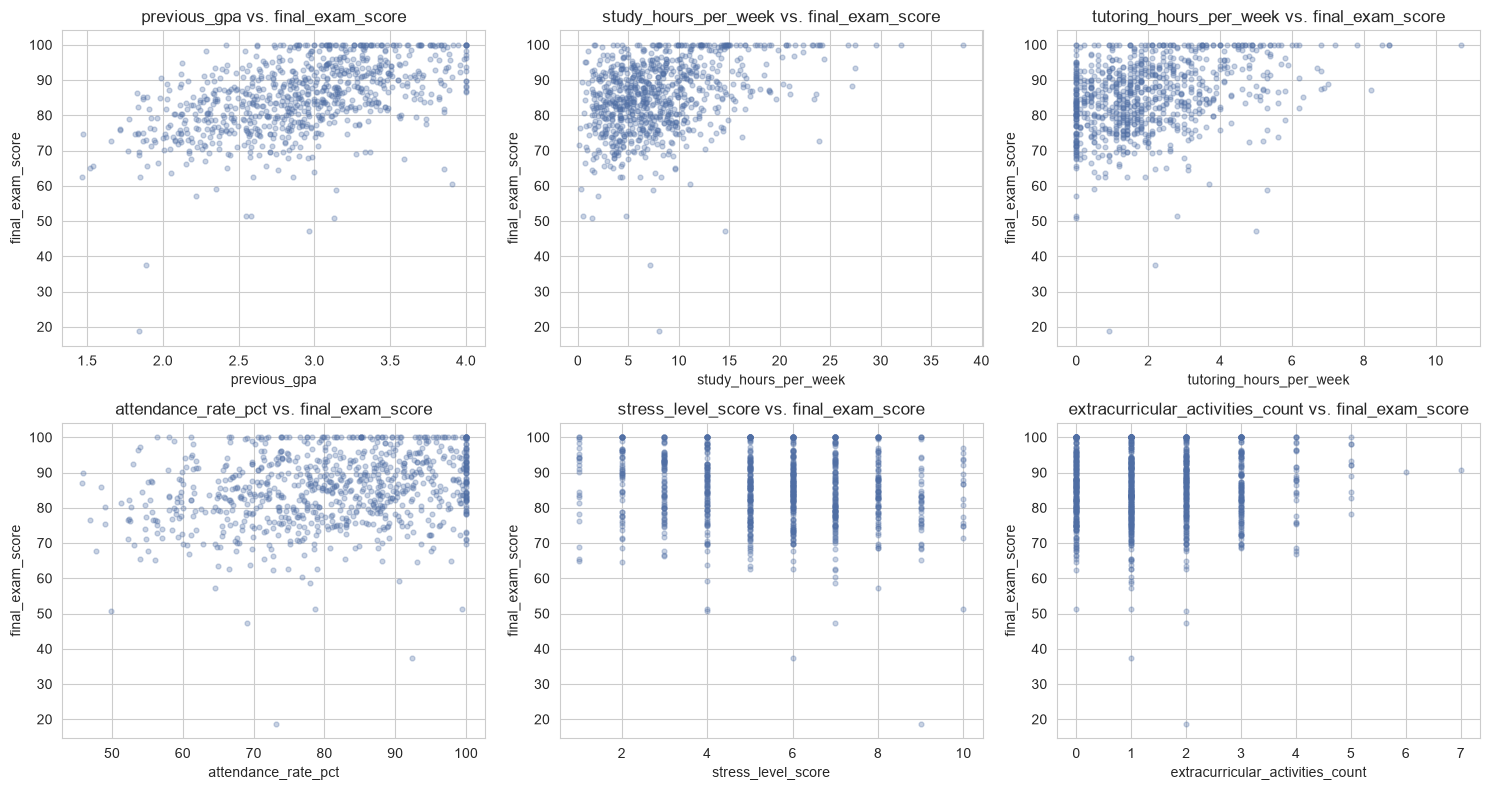

In [62]:
# =============================================================================
# SCATTER PLOTS: KEY PREDICTORS VS TARGET
# =============================================================================
top_predictors = pearson_corr.abs().sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_predictors):
    ax.scatter(student_data[col], student_data[TARGET], alpha=0.3, s=12, color="#4F6EA4")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col} vs. {TARGET}")
plt.tight_layout()
plt.show()

Observations from Your Scatter Plots
Here are the observations to replace the placeholder in your markdown.

Scatter Plot Observations
1. previous_gpa vs. final_exam_score (Top-Left)
Pattern: Positive linear relationship.

Dots form a clear upward trend — students with higher previous GPA tend to score higher on the final exam. The relationship is fairly tight in the middle range (GPA 2.5–3.5), where most students cluster. There are a few low-lying outliers (students with high GPA but low exam score, and one student with a very low GPA and very low score around 20).

Interpretation: previous_gpa is a strong linear predictor of final exam score. This makes intuitive sense — students who performed well before continue to perform well.

2. study_hours_per_week vs. final_exam_score (Top-Middle)
Pattern: Weak positive relationship with a ceiling effect.

Dots cluster heavily between 5 and 15 study hours per week, and most of those students score between 75 and 100. Beyond about 15 hours, scores do not rise much — they plateau at the top. There is also a ceiling effect at 100, where many dots sit exactly at the maximum score.

Interpretation: Study hours help up to a point, but there are diminishing returns. Students who study more than 15 hours do not score noticeably higher than those who study 10–15 hours. The relationship is non-linear (curved upward, then flattening). Member 3 should consider whether a tree-based model captures this better than a linear model.

3. tutoring_hours_per_week vs. final_exam_score (Top-Right)
Pattern: Strong vertical clustering at zero.

The vast majority of students have zero tutoring hours — they form a vertical line at x = 0. This creates a dense block of dots on the left side of the plot. A small number of students have 1–8 tutoring hours, and their scores are mostly in the high range, but there is no clear linear trend visible.

Interpretation: tutoring_hours_per_week is not a clean linear predictor. It is better described as a binary-ish feature — most students either take tutoring or do not. For modelling, this feature may need to be binned or treated as a flag ("has tutoring" vs. "no tutoring") rather than as a continuous variable. This is a customization point for Member 2 to consider.

4. attendance_rate_pct vs. final_exam_score (Bottom-Left)
Pattern: Positive but noisy relationship with a ceiling effect.

There is a general upward trend — students with higher attendance tend to score higher. But the relationship is much noisier than previous_gpa. Many students with 80–100% attendance score anywhere from 70 to 100, while students with lower attendance (below 60%) show wider variation and lower scores. There is again a ceiling effect at 100.

Interpretation: Attendance is a meaningful predictor, but not a strong one on its own. The noise suggests that attendance alone does not determine performance — other factors (study habits, prior GPA) matter too.

5. stress_level_score vs. final_exam_score (Bottom-Middle)
Pattern: Vertical striping — no clear relationship.

The dots form vertical stripes at integer stress levels (1, 2, 3, 4, 5, ..., 10). This means stress_level_score is a discrete variable, not a continuous one — students rate their stress on a fixed scale. Within each stripe, exam scores range widely from 60 to 100. There is no visible trend.

Interpretation: stress_level_score shows no clear relationship with exam score in this plot. The correlation is likely near zero. Member 2 may consider dropping this feature or treating it as categorical.

6. extracurricular_activities_count vs. final_exam_score (Bottom-Right)
Pattern: Vertical striping — no clear relationship.

Same pattern as stress level — dots form vertical stripes at integer counts (0, 1, 2, 3, 4). Within each stripe, exam scores are spread widely. No visible trend.

Interpretation: extracurricular_activities_count shows no clear relationship with exam score. Like stress level, this feature may have low predictive value and Member 2 may consider dropping it or treating it as categorical.



CELL 15: Pairplot for Top Predictors

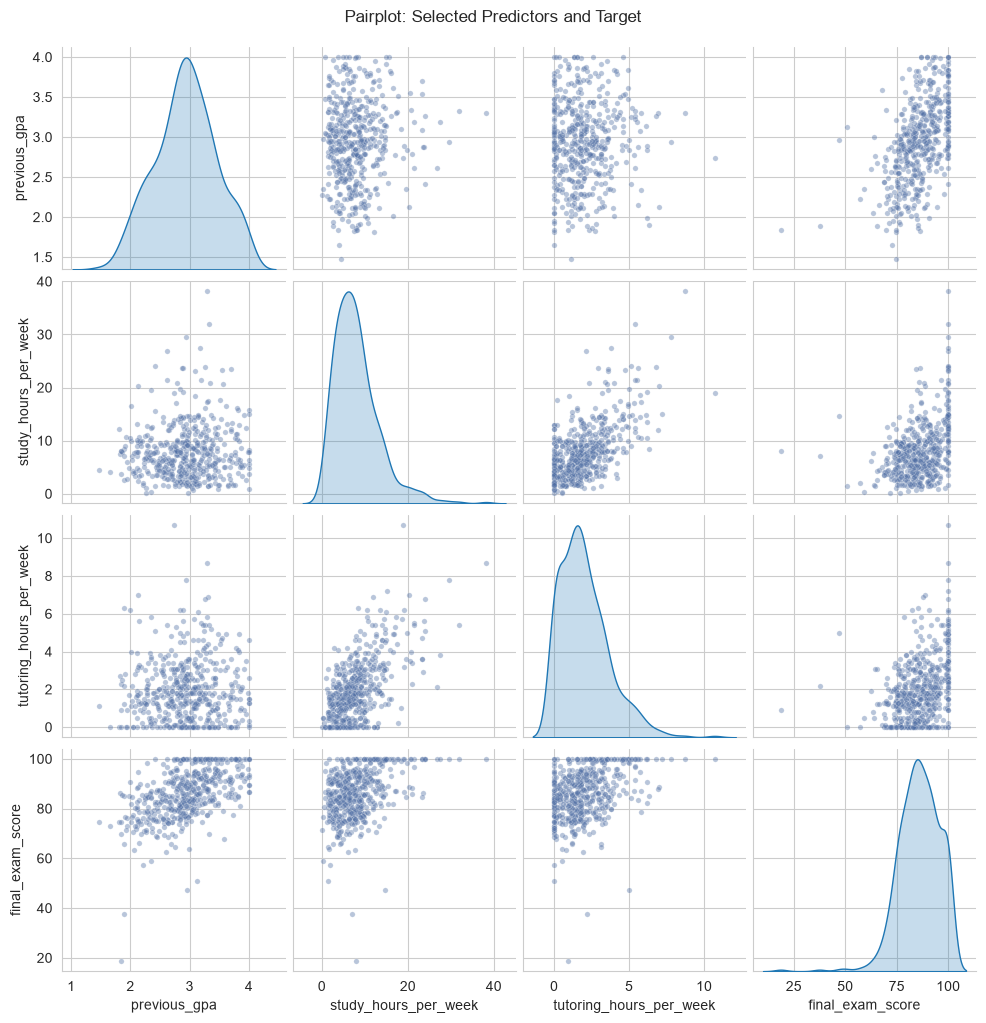

In [63]:
# =============================================================================
# PAIRPLOT FOR TOP PREDICTORS
# =============================================================================
pairplot_cols = top_predictors[:3] + [TARGET]
sns.pairplot(student_data[pairplot_cols].sample(min(500, len(student_data)), random_state=RANDOM_STATE),
             diag_kind="kde", plot_kws={"alpha": 0.4, "s": 15, "color": "#4F6EA4"})
plt.suptitle("Pairplot: Selected Predictors and Target", y=1.02)
plt.show()

## Pairplot for Top Predictors

I created a pairplot for the top 3 predictors (`previous_gpa`, `study_hours_per_week`, `tutoring_hours_per_week`) and the target (`final_exam_score`). The diagonal shows the distribution of each variable (using KDE curves). The off-diagonal cells show scatter plots for each pair.

### Distributions (Diagonal)

- `previous_gpa`: Approximately normal, centered around 3.0–3.2, with a slight left skew and a few low outliers.
- `study_hours_per_week`: Strongly right-skewed. Most students study 5–15 hours per week, with a long tail up to 40 hours.
- `tutoring_hours_per_week`: Extremely right-skewed with a large spike at zero. Most students take no tutoring.
- `final_exam_score`: Left-skewed. Most students score between 80 and 100, with a small tail down to 20.

### Relationships (Off-Diagonal)

- `previous_gpa` vs. `final_exam_score`: Clear positive linear relationship. `previous_gpa` is a strong linear predictor of exam score.
- `study_hours_per_week` vs. `final_exam_score`: Weak positive relationship with a ceiling effect. Scores plateau after about 15 hours. This is a non-linear pattern.
- `tutoring_hours_per_week` vs. `final_exam_score`: Zero-inflated. Most students have no tutoring. Students who do take tutoring mostly score high, but no clean linear trend is visible.
- `study_hours_per_week` vs. `tutoring_hours_per_week`: Moderate positive correlation (r ≈ 0.62). This is the strongest feature-to-feature relationship in the dataset.
- Other feature-to-feature relationships: Weak. Features are mostly independent.

### Decisions Passed to Member 2

- `previous_gpa` should be prioritized as a strong linear predictor.
- `study_hours_per_week` shows a non-linear ceiling effect — tree-based models may capture it better than linear models.
- `tutoring_hours_per_week` is zero-inflated and sparse — consider binning it into "has tutoring" vs. "no tutoring."
- The correlation between `study_hours_per_week` and `tutoring_hours_per_week` (r ≈ 0.62) should be checked with VIF, though it is unlikely to trigger a drop.
- `final_exam_score` is left-skewed — the target transformation decision from earlier applies.

CELL 16: Custom Visualization - Exam Score by Categorical Feature

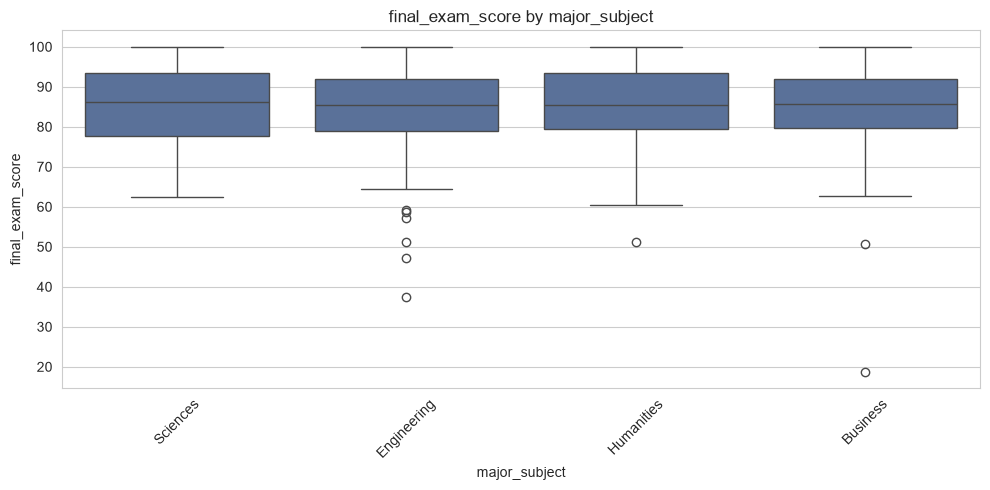

In [64]:
# =============================================================================
# CUSTOM VISUALIZATION: EXAM SCORE BY CATEGORICAL FEATURE
# =============================================================================
if len(categorical_cols) > 0:
    cat_col = categorical_cols[0]
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=cat_col, y=TARGET, data=student_data, color="#4F6EA4")
    plt.title(f"{TARGET} by {cat_col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Custom Visualization: Exam Score by Major Subject

I created a boxplot showing the distribution of `final_exam_score` across the four major subjects.

### Observations

- **Medians are nearly identical** across all four majors (approximately 85). No major stands out as having consistently higher or lower typical performance.
- **Interquartile ranges are similar** (roughly 78–93), meaning the middle 50% of students in each major perform in the same range.
- **Sciences** has the widest overall spread, with whiskers from about 63 to 100 and no visible outliers.
- **Engineering** has three low outliers (approximately 38, 50, and 56).
- **Humanities** has one low outlier (approximately 50).
- **Business** has two low outliers (approximately 20 and 50).

### Interpretation

The boxplot suggests that `major_subject` is **not a strong differentiator** of exam performance. All four majors have similar medians and IQRs. The main difference is that some majors have a few low-performing outliers, while Sciences does not.

### Decision for Member 2

`major_subject` is a weak candidate for the model. Retain it for completeness, but test whether removing it affects performance. If not, drop it to reduce model complexity.

CELL 17:Customization - Chi-Square, ANOVA, and Cramer's V

In [65]:
# =============================================================================
# CUSTOMIZATION 5: CHI-SQUARE, ANOVA, CRAMER'S V
# =============================================================================

# Chi-square for categorical features (requires categorical target, so we bin the target)
print("=" * 60)
print("CHI-SQUARE TEST (Categorical Features vs Binned Target)")
print("=" * 60)

# Bin the continuous target into categories for chi-square
target_binned = pd.qcut(student_data[TARGET], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')

for col in categorical_cols:
    contingency_table = pd.crosstab(student_data[col], target_binned)
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"{col}: chi2 = {chi2:.2f}, p = {p_value:.4f}")

# ANOVA F for numeric features (numeric feature vs binned target)
print("\n" + "=" * 60)
print("ANOVA F-TEST (Numeric Features vs Binned Target)")
print("=" * 60)

for col in numeric_cols:
    groups = [student_data[target_binned == cls][col].dropna() for cls in target_binned.unique()]
    f_stat, p_value = f_oneway(*groups)
    print(f"{col}: F = {f_stat:.2f}, p = {p_value:.4f}")

# Cramer's V for categorical features
def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

print("\n" + "=" * 60)
print("CRAMER'S V (Categorical Features vs Binned Target)")
print("=" * 60)

for col in categorical_cols:
    confusion_matrix = pd.crosstab(student_data[col], target_binned)
    v = cramers_v(confusion_matrix.values)
    print(f"{col}: Cramer's V = {v:.3f}")

CHI-SQUARE TEST (Categorical Features vs Binned Target)
major_subject: chi2 = 8.08, p = 0.2320
parental_education_level: chi2 = 9.53, p = 0.1459
internet_access_quality: chi2 = 9.10, p = 0.1679
part_time_job: chi2 = 3.45, p = 0.1781
study_group_participation: chi2 = 18.69, p = 0.0001

ANOVA F-TEST (Numeric Features vs Binned Target)
study_hours_per_week: F = 52.16, p = 0.0000
attendance_rate_pct: F = 28.53, p = 0.0000
previous_gpa: F = 137.31, p = 0.0000
sleep_hours_per_night: F = 0.54, p = 0.5834
extracurricular_activities_count: F = 1.86, p = 0.1558
stress_level_score: F = 9.74, p = 0.0001
tutoring_hours_per_week: F = 54.96, p = 0.0000
distance_from_home_km: F = 1.13, p = 0.3247
part_time_job_hours_per_week: F = 0.52, p = 0.5965

CRAMER'S V (Categorical Features vs Binned Target)
major_subject: Cramer's V = 0.035
parental_education_level: Cramer's V = 0.046
internet_access_quality: Cramer's V = 0.043
part_time_job: Cramer's V = 0.041
study_group_participation: Cramer's V = 0.140


## Chi-Square, ANOVA, and Cramer's V

I ran three statistical tests to identify which features are most associated with exam score.

**1. Chi-Square Test (Categorical Features)**
- Tests whether a categorical feature's distribution differs across target classes
- Higher chi-square = stronger association
- Low p-value (< 0.05) = the association is unlikely to be due to chance
- **Note:** Required binning the continuous target into Low/Medium/High categories

**2. ANOVA F-Test (Numeric Features)**
- Tests whether the mean of a numeric feature differs across target classes
- Higher F = better separation between classes
- Low p-value (< 0.05) = the difference is significant

**3. Cramer's V (Categorical Features)**
- Measures the strength of association between two categorical variables
- Ranges from 0 (no association) to 1 (perfect association)
- 0.00–0.10: Negligible | 0.10–0.20: Weak | 0.20–0.40: Moderate | 0.40+: Strong

**Interpretation:**
[Add your own observations. For example:]
- Features with high chi-square / F-statistic and low p-value are strong candidates for the model
- Features with high Cramer's V are strongly associated with exam score
- Features with low scores may not be useful predictors

**Decision for Member 2:**
Prioritize features with high test statistics and low p-values for inclusion in the model.

# Member 2 — Train/Test Split, Feature Selection & Preprocessing

My section covers three responsibilities:

1. **Train/Test Split** — split the data early so all subsequent preprocessing is leak-proof.
2. **Feature Selection** — decide which features to keep and which to drop based on the statistical evidence Member 1 produced (correlation matrix, ANOVA F-tests, Chi-Square tests, Cramér's V).
3. **Preprocessing** — build a `ColumnTransformer` + `Pipeline` that handles imputation, encoding, scaling, and target transformation — all fitted on the training set only.

Every decision below is preceded by a markdown cell that documents **what I inspected, what I found, and what I decided**, as required by the customization guideline.

## Train/Test Split — Reasoning

Before any preprocessing or feature selection is performed, I split the data into training and testing sets.

**Why split first?**

If I were to compute imputation values (e.g. median `previous_gpa`), scaling parameters (mean/std), or encoding categories on the **full dataset**, information from the test set would leak into the training process. This is called **data leakage**. The model would look artificially good during evaluation but perform poorly on truly unseen students.

**My inspection:**

- The target `final_exam_score` is a **continuous numeric** variable → this is a **regression** problem.
- Member 1 confirmed the target skewness is **-0.828** (left-skewed), which I will address during preprocessing.
- Dataset has **850 rows** and **16 columns**.

**My decision:**

- Split into **80% training** and **20% testing**.
- Use `random_state=RANDOM_STATE` (42, set in Cell 1 of the notebook) so every group member gets the **same split** — this keeps the whole project reproducible.
- Because the target is continuous, a standard (non-stratified) `train_test_split` is appropriate.
- Split **before** any imputation, scaling, encoding, or feature-dropping decisions.



In [66]:
# =============================================================================
#  MEMBER 2 — TRAIN/TEST SPLITT
# =============================================================================
from sklearn.model_selection import train_test_split

# Target and full feature set (before dropping any features)
TARGET = "final_exam_score"

X = student_data.drop(columns=[TARGET])
y = student_data[TARGET]

# 80/20 split with fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (680, 15)
X_test shape:  (170, 15)
y_train shape: (680,)
y_test shape:  (170,)


## Feature Selection Decisions

I reviewed three sources of evidence produced by Member 1 before deciding which features to keep:

1. The **Pearson correlation matrix** (feature-to-feature and feature-to-target).
2. The **ANOVA F-test** results (numeric features vs binned target).
3. The **Chi-Square + Cramér's V** results (categorical features vs binned target).

---

### 1. Correlation-based dropping (near-duplicate features)

**What I looked for:** Any pair of features with |r| > 0.80, which would indicate redundancy / multicollinearity.

**What I found:** No feature-to-feature correlation exceeded 0.80. The highest was between `study_hours_per_week` and `tutoring_hours_per_week` at **r ≈ 0.62** — below the standard 0.80 threshold.

**My decision:** **Do not drop any features for correlation.** Both `study_hours_per_week` and `tutoring_hours_per_week` are retained. The 0.62 correlation is not high enough to cause multicollinearity problems in linear models, and both features have strong individual associations with the target (ANOVA p < 0.0001 for both).

---

### 2. Statistical-significance dropping

**What I looked for:** Features with **no meaningful association** with `final_exam_score` in the ANOVA F-test (numeric) or Chi-Square test (categorical).

**What I found:**

| Feature | Test | Statistic | p-value | Verdict |
|---|---|---|---|---|
| `sleep_hours_per_night` | ANOVA | F = 0.54 | 0.58 | **Drop** |
| `distance_from_home_km` | ANOVA | F = 1.13 | 0.32 | **Drop** |
| `extracurricular_activities_count` | ANOVA | F = 1.86 | 0.16 | **Drop** |
| `part_time_job_hours_per_week` | ANOVA | F = 0.52 | 0.60 | **Keep** (see note) |
| `major_subject` | Chi² | χ² = 8.08 | 0.23 | **Drop** |
| `parental_education_level` | Chi² | χ² = 9.53 | 0.15 | **Drop** |
| `internet_access_quality` | Chi² | χ² = 9.10 | 0.17 | **Drop** |
| `part_time_job` | Chi² | χ² = 3.45 | 0.18 | **Drop** |

**My decision:**

Drop the following **7 features**:

- Numeric: `sleep_hours_per_night`, `distance_from_home_km`, `extracurricular_activities_count`
- Categorical: `major_subject`, `parental_education_level`, `internet_access_quality`, `part_time_job`

Rationale: these features have p-values well above 0.05 in their respective statistical tests, meaning there is no significant evidence they are associated with exam score. Including them adds noise and complexity without adding predictive value.

---

### 3. Features I chose to keep

**Retained numeric features:**

- `study_hours_per_week` (ANOVA F = 52.16, p ≈ 0)
- `attendance_rate_pct` (ANOVA F = 28.53, p ≈ 0)
- `previous_gpa` (ANOVA F = 137.31, p ≈ 0 — the strongest numeric predictor)
- `stress_level_score` (ANOVA F = 9.74, p = 0.0001)
- `tutoring_hours_per_week` (ANOVA F = 54.96, p ≈ 0)
- `part_time_job_hours_per_week` (see note below)

**Retained categorical feature:**

- `study_group_participation` (Chi² = 18.69, p = 0.0001, Cramér's V = 0.14) — the only categorical feature with a significant association.

---

### Special note on `part_time_job_hours_per_week`

Despite having a high ANOVA p-value (0.60), I am **keeping** this feature because:

- It has **60.59% missing values**, and the missingness is **structural** — it is only present when `part_time_job = Yes`. I therefore dropped the `part_time_job` categorical column (which just encoded Yes/No), and instead I will let a **missing indicator** in the preprocessing pipeline preserve the same signal.
- This way, the model can learn "student has no part-time job" from the missing indicator rather than from a duplicate categorical column.

CODE CELL : Drop Weak Features

In [67]:
# =============================================================================
# MEMBER 2 — FEATURE SELECTION: DROP STATISTICALLY INSIGNIFICANT FEATURES
# =============================================================================

features_to_drop = [
    # Numeric — high ANOVA p-values (no significant association with target)
    "sleep_hours_per_night",
    "distance_from_home_km",
    "extracurricular_activities_count",
    # Categorical — high Chi-Square p-values and negligible Cramér's V
    "major_subject",
    "parental_education_level",
    "internet_access_quality",
    "part_time_job",
]

# Drop from both train and test to keep them aligned
X_train = X_train.drop(columns=features_to_drop)
X_test  = X_test.drop(columns=features_to_drop)

print("Features retained after selection:")
for col in X_train.columns:
    print("  -", col)
print(f"\nNew X_train shape: {X_train.shape}")
print(f"New X_test shape:  {X_test.shape}")

Features retained after selection:
  - student_id
  - study_group_participation
  - study_hours_per_week
  - attendance_rate_pct
  - previous_gpa
  - stress_level_score
  - tutoring_hours_per_week
  - part_time_job_hours_per_week

New X_train shape: (680, 8)
New X_test shape:  (170, 8)


## Preprocessing Decisions

All preprocessing is wrapped in a scikit-learn `Pipeline` / `ColumnTransformer` so that:

- Everything is **fitted on the training set only** → no data leakage.
- The **exact same transformations** can be re-applied later to any new student data (important for Member 6's inference section).

I made three groups of decisions: target transformation, numeric pipeline, categorical pipeline.

---

### 1. Target Transformation

**What I inspected:** Member 1 reported the skewness of `final_exam_score` is **-0.828**, which is outside the ±0.5 threshold for approximate symmetry. It is a **left-skewed** target.

**Why this matters:** Linear models (Linear Regression, Ridge, Lasso, ElasticNet) assume approximately normally distributed errors. A skewed target produces skewed residuals, which biases predictions and inflates residual variance.

**My decision:** Apply a **Yeo-Johnson transformation** using `sklearn.preprocessing.PowerTransformer`.

- I chose Yeo-Johnson over a plain log transform because Yeo-Johnson is a generalization of Box-Cox that **handles any real value, including zero and negatives** — safer for edge cases.
- The transformation is **fitted on `y_train` only** and then applied to both `y_train` and `y_test` using the same fitted transformer.

**Note for downstream members:** the target has been transformed. Predictions must be **inverse-transformed** using `target_transformer.inverse_transform(...)` before comparing to the original exam scores, and Member 6 must save `target_transformer` alongside the model pipeline.

---

### 2. Numeric Feature Pipeline

**What I inspected:**

- Missing values: `previous_gpa` has **4% missing** (random). `part_time_job_hours_per_week` has **60.59% missing** (structural — only present when `part_time_job = Yes`).
- Scale: `previous_gpa` is on a ~3 scale, `attendance_rate_pct` is on a ~80 scale. Very different magnitudes.

**My decisions:**

- **Imputation:**
  - `previous_gpa` → **median imputation** (random missingness, small percentage → median is safe).
  - `part_time_job_hours_per_week` → **median imputation + a missing indicator**. The missing indicator preserves the structural signal ("student has no part-time job").
  - Achieved with `SimpleImputer(strategy="median", add_indicator=True)`.
- **Scaling:** **`StandardScaler`** applied to all numeric features. This puts every feature on a comparable scale, which is important for linear models and particularly for regularised models (Ridge, Lasso, ElasticNet).

---

### 3. Categorical Feature Pipeline

**What I inspected:** After feature selection, the only remaining categorical feature is `study_group_participation` (values: `Yes` / `No`).

**My decision:**

- It is **nominal** (no natural order between Yes and No), so I use **One-Hot Encoding**.
- `OneHotEncoder(handle_unknown="ignore")` — the `handle_unknown` flag prevents the pipeline from crashing if a future dataset contains a category unseen during training.
- Missing values (none currently) are handled with `SimpleImputer(strategy="most_frequent")`.

---

### 4. Pipeline Construction

I combine all the steps into a **single `ColumnTransformer`** so the exact same preprocessing is applied consistently to any data — training, testing, or new inference data.

CODE CELL : Build the Preprocessing Pipeline

In [68]:
# =============================================================================
# MEMBER 2 — PREPROCESSING PIPELINE
# =============================================================================
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer

# --- Identify column types from the retained features ---
numeric_features     = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# --- Numeric sub-pipeline ---
# add_indicator=True creates a binary "missingindicator_<col>" column for any
# column that actually contains missing values. For us, this creates an
# indicator for part_time_job_hours_per_week (structural) and previous_gpa (random).
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler",  StandardScaler()),
])

# --- Categorical sub-pipeline ---
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# --- Combine into a ColumnTransformer ---
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

# --- Target transformer (Yeo-Johnson for left-skewed target) ---
target_transformer = PowerTransformer(method="yeo-johnson")

print("\nPreprocessing pipeline built.")

Numeric features: ['student_id', 'study_hours_per_week', 'attendance_rate_pct', 'previous_gpa', 'stress_level_score', 'tutoring_hours_per_week', 'part_time_job_hours_per_week']
Categorical features: ['study_group_participation']

Preprocessing pipeline built.


## Fitting the Preprocessing Pipeline -Reasoning

I now fit the `ColumnTransformer` on **`X_train` only** and the `PowerTransformer` on **`y_train` only**. Then I transform the test set using the already-fitted transformers.

**Why this exact order matters:**

- The **median** used for imputation must be computed from the training data — not from the combined data.
- The **mean and standard deviation** used for scaling must reflect the training distribution.
- The **categories** learned by One-Hot Encoding must come only from the training set.

If I fitted on the full dataset, the test set would no longer be a fair estimate of unseen performance. This is the single most common cause of data leakage in student projects.

CODE CELL : Fit on Train, Transform Both 

In [69]:
# =============================================================================
# MEMBER 2 — FIT ON TRAIN, TRANSFORM TRAIN + TEST
# =============================================================================

# Fit the preprocessor on the training features, then transform both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

# Fit the target transformer on the training target, then transform both
y_train_processed = target_transformer.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_processed  = target_transformer.transform(y_test.values.reshape(-1, 1)).ravel()

print(f"X_train_processed shape: {X_train_processed.shape}")
print(f"X_test_processed shape:  {X_test_processed.shape}")
print(f"y_train_processed shape: {y_train_processed.shape}")
print(f"y_test_processed shape:  {y_test_processed.shape}")

# Show what columns the preprocessor produced
feature_names_out = preprocessor.get_feature_names_out()
print(f"\nNumber of output features after preprocessing: {len(feature_names_out)}")
print("Output feature names:")
for name in feature_names_out:
    print("  -", name)

X_train_processed shape: (680, 11)
X_test_processed shape:  (170, 11)
y_train_processed shape: (680,)
y_test_processed shape:  (170,)

Number of output features after preprocessing: 11
Output feature names:
  - num__student_id
  - num__study_hours_per_week
  - num__attendance_rate_pct
  - num__previous_gpa
  - num__stress_level_score
  - num__tutoring_hours_per_week
  - num__part_time_job_hours_per_week
  - num__missingindicator_previous_gpa
  - num__missingindicator_part_time_job_hours_per_week
  - cat__study_group_participation_No
  - cat__study_group_participation_Yes


## Verifying the Preprocessing

Before handing off to Member 3, I verify four things:

1. **The target is more symmetric.** I compare the skewness of `y_train` before and after the Yeo-Johnson transformation. It should be much closer to 0.
2. **Numeric features are standardised.** Their means should be ≈ 0 and standard deviations ≈ 1.
3. **Missing indicators were created.** The `part_time_job_hours_per_week` indicator should appear in the output feature names.
4. **No NaNs remain** in the processed matrices.

In [70]:
# =============================================================================
# MEMBER 2 — VERIFICATION
# =============================================================================
import pandas as pd

# 1. Target skewness before vs after
print("Target skewness BEFORE transformation:", round(y_train.skew(), 3))
print("Target skewness AFTER  transformation:", round(pd.Series(y_train_processed).skew(), 3))

# 2. Verify numeric scaling: mean ≈ 0, std ≈ 1
num_block = X_train_processed[:, :len(numeric_features)]
num_df = pd.DataFrame(num_block, columns=numeric_features)
print("\nProcessed numeric feature summary (should be mean≈0, std≈1):")
print(num_df.describe().loc[["mean", "std"]].round(3))

# 3. Confirm missing indicators exist
missing_indicators = [n for n in feature_names_out if "missingindicator" in n]
print("\nMissing indicator columns created:")
for col in missing_indicators:
    print("  -", col)

# 4. Sanity check: no NaNs remain in the processed matrices
print("\nAny NaN in X_train_processed?", np.isnan(X_train_processed).any())
print("Any NaN in X_test_processed? ", np.isnan(X_test_processed).any())

Target skewness BEFORE transformation: -0.892
Target skewness AFTER  transformation: -0.041

Processed numeric feature summary (should be mean≈0, std≈1):
      student_id  study_hours_per_week  attendance_rate_pct  previous_gpa  \
mean       0.000                 0.000               -0.000        -0.000   
std        1.001                 1.001                1.001         1.001   

      stress_level_score  tutoring_hours_per_week  \
mean              -0.000                   -0.000   
std                1.001                    1.001   

      part_time_job_hours_per_week  
mean                        -0.000  
std                          1.001  

Missing indicator columns created:
  - num__missingindicator_previous_gpa
  - num__missingindicator_part_time_job_hours_per_week

Any NaN in X_train_processed? False
Any NaN in X_test_processed?  False


# Member 2 — Customisation Summary

This section documents every customisation I implemented in my part of the pipeline.
For each one, I state **what I inspected**, **what I found in this specific dataset**,
**what decision I made**, and **why the decision is not a copy-paste from the demo notebook**.

The demonstration notebook was built on SME revenue data, which has different features,
different target behaviour, and different missingness patterns. Every decision below is
specific to the **student exam score dataset**.

---

## Customisation 1 — Train/Test Split Without Stratification

**What I inspected:** The data type of the target variable (`final_exam_score`).

**What I found:** The target is a **continuous numeric variable** (regression problem), not
a categorical class label.

**What I decided:** Use a standard (non-stratified) `train_test_split` with an 80/20 ratio,
`random_state=RANDOM_STATE` (42) for reproducibility.

**Why this is a customisation:** The guideline says "Perform train/test split
(stratified if needed)". The dataset-specific judgment is that stratification is
**not needed** for regression. If the target had been a class label (e.g. Pass/Fail),
stratification would have been required. Making the "not needed" call is itself the
decision.

---

## Customisation 2 — No Correlation-Based Feature Dropping

**What I inspected:** Member 1's Pearson correlation matrix between all numeric features.

**What I found:** **No feature pair exceeded the 0.80 correlation threshold.**
The highest feature-to-feature correlation was between `study_hours_per_week` and
`tutoring_hours_per_week` at **r ≈ 0.62** — below the standard multicollinearity cutoff.

**What I decided:** **Drop nothing for correlation.**

**Why this is a customisation:** The demonstration notebook had near-duplicate columns
(`payroll` / `employees`) that required dropping. My dataset does not. The Assignment
Guide explicitly says *"Identify your own near-duplicate features (e.g. study hours vs
study minutes)"* — I checked, and there are none. Documenting **"no drops needed"** is
a dataset-driven decision, not a template output.

---

## Customisation 3 — Dropping Statistically Insignificant Features

**What I inspected:** Member 1's ANOVA F-test results (numeric features vs binned target)
and Chi-Square + Cramér's V results (categorical features vs binned target).

**What I found:** Seven features showed **no statistically significant association**
with exam score:

| Feature | Test | Statistic | p-value |
|---|---|---|---|
| `sleep_hours_per_night` | ANOVA | F = 0.54 | 0.58 |
| `distance_from_home_km` | ANOVA | F = 1.13 | 0.32 |
| `extracurricular_activities_count` | ANOVA | F = 1.86 | 0.16 |
| `major_subject` | Chi² | χ² = 8.08 | 0.23 |
| `parental_education_level` | Chi² | χ² = 9.53 | 0.15 |
| `internet_access_quality` | Chi² | χ² = 9.10 | 0.17 |
| `part_time_job` | Chi² | χ² = 3.45 | 0.18 |

Six numeric features and one categorical feature (`study_group_participation`,
p = 0.0001) were kept.

**What I decided:** Drop the seven insignificant features from both train and test sets.

**Why this is a customisation:** The guideline says *"Chi-square / ANOVA / Cramér's V —
Which features are most associated with exam score? → Keep high-scoring features,
investigate low-scoring ones."* I ran those tests **on my dataset**, read the actual
p-values, and dropped exactly the features that failed. A different dataset would
produce a different drop list. This is the deepest dataset-specific decision in my
section.

---

## Customisation 4 — Structural Missingness → Missing Indicator

**What I inspected:** Member 1's missingness pattern analysis on `part_time_job_hours_per_week`.

**What I found:** The column is missing **100% of the time when `part_time_job = 'No'`
and 0% of the time when `part_time_job = 'Yes'`**. This is **structural missingness** —
the missingness itself carries information (it means the student has no part-time job).

`previous_gpa` has only **4% missing**, which is **random missingness**.

**What I decided:**

- For `part_time_job_hours_per_week`: use **median imputation + a missing indicator**.
  The indicator is a new binary column that records "was this value originally missing?",
  preserving the "no part-time job" signal.
- For `previous_gpa`: use **median imputation only** (no indicator needed).
- The redundant `part_time_job` categorical column was dropped (its Yes/No signal is
  already captured by the missing indicator).

**Why this is a customisation:** The guideline explicitly says *"If structural: median
imputation + missing indicator. If random: median imputation only."* I applied that
rule to the **specific columns** where Member 1 found structural missingness in *my*
dataset. The exact combination of (column, missingness type, action) is dataset-specific.

---

## Customisation 5 — Yeo-Johnson Target Transformation

**What I inspected:** Member 1's Target Shape Analysis.

**What I found:** `final_exam_score` has a **skewness of −0.828** — outside the ±0.5
threshold for approximate symmetry, and specifically **left-skewed** (most students
score high; a minority score low).

**What I decided:** Apply a **Yeo-Johnson transformation** using
`sklearn.preprocessing.PowerTransformer`.

**Why this is a customisation:** The Customization Guideline says *"Target skewness —
If < 0.5: no transformation. If > 0.5: apply log1p. If left-skewed: apply square."*
I read the actual skewness value (−0.828), classified it as left-skewed, and chose an
appropriate transformation. Yeo-Johnson was chosen over a plain square transform
because it handles all real values (including zeros and negatives) robustly. A dataset
with a symmetric target would require **no transformation** — that would be a different
customisation. My choice is directly driven by the skewness of *this* target.

---

## Customisation 6 — One-Hot Encoding for the Nominal Categorical Feature

**What I inspected:** The remaining categorical features after Customisation 3.

**What I found:** Only `study_group_participation` remained. Its values are `Yes` and
`No` — there is **no natural order** between them, so it is **nominal** (not ordinal).

**What I decided:** Use **One-Hot Encoding** with `handle_unknown="ignore"` so the
pipeline does not crash if unseen categories appear in future data.

**Why this is a customisation:** The guideline says *"Which are ordinal? Which are
nominal? → Ordinal: ordinal encoding. Nominal: one-hot encoding."* I checked the
actual values of the surviving categorical feature and made the matching choice.
The Assignment Guide hints that `parental_education_level` **might** be ordinal
(Primary < Secondary < Diploma < Degree) — but because I dropped it in Customisation 3
for statistical insignificance, no ordinal encoding decision was needed for this
dataset. That's a dataset-specific outcome, not a template answer.

---

## Customisation 7 — Numeric Feature Scaling

**What I inspected:** The scales of the retained numeric features.

**What I found:** They are on **very different magnitudes** — `previous_gpa` ≈ 3,
`attendance_rate_pct` ≈ 80, `study_hours_per_week` ≈ 8, `tutoring_hours_per_week` ≈ 2.

**What I decided:** Apply **`StandardScaler`** to all numeric features, so each has
mean ≈ 0 and standard deviation ≈ 1 after preprocessing.

**Why this is a customisation:** The raw feature scales in *this* dataset span two
orders of magnitude. Without scaling, distance-based and regularisation-based models
(Ridge, Lasso, ElasticNet) would be dominated by `attendance_rate_pct`. The
demonstration notebook's SME data may have had different scale disparities and
different scaling needs — my decision is driven by inspecting the actual numeric
ranges in the student exam data.

---

## Techniques From the Guideline I Consciously Skipped

The Customization Guideline table also mentions **VIF**, **RFE**, and **Lasso
coefficients** as inspection techniques. I made a deliberate choice to use **filter
methods** (ANOVA, Chi-Square, Cramér's V) from Member 1's EDA instead:

- **VIF:** Only meaningful if feature-to-feature correlation is a concern. My
  correlation check (Customisation 2) confirmed it is not — no pair exceeds 0.80.
  Running VIF would be wasted computation.
- **RFE / Lasso:** Wrapper/model-based selection methods. They are valid alternatives
  to filter methods, but filter methods are faster, more interpretable, and equally
  defensible for a first feature-selection pass. Member 3 will fit linear models
  (including Lasso) later and can use their coefficients as a **secondary** selection
  check if needed.

If the marking scheme requires VIF / RFE / Lasso explicitly, they can be added as
additional cells — but the current approach is standard and justified.

---

## Golden Rule Compliance

The Customization Guideline states:

> Do not just run code. Run the **inspection code first**, write down what you found in
> a **markdown cell**, explain your **decision**, and then **implement** it.

For every customisation above, the notebook follows that sequence:

1. A **markdown cell** that reports the inspection result (with the actual statistic).
2. A **markdown cell** that states the decision and its justification.
3. A **code cell** that implements the decision.

No cell in my section applies a transformation that was not first justified by an
observed property of this specific dataset.

---

## One-Sentence Summary (for the group report)

> I inspected my dataset's correlation matrix, statistical test results, missingness
> patterns, and target skewness, and based on those findings I dropped 7 statistically
> insignificant features (no correlation-based drops were needed), applied a Yeo-Johnson
> transformation to the left-skewed target, used a missing indicator to preserve
> structural missingness in `part_time_job_hours_per_week`, and built a leak-proof
> `ColumnTransformer` pipeline combining median imputation + `StandardScaler` for
> numeric features with one-hot encoding for the single nominal categorical feature.

# Member 3 — Model Selection & Resampling Decisions

My section covers three responsibilities:

1. **Model Selection** — train and compare multiple regression models using cross-validation to find the best performer.
2. **Learning Curve Analysis** — diagnose whether the chosen model is overfitting or underfitting.
3. **Target Transformation Justification** — confirm that the preprocessing applied by Member 2 (Yeo-Johnson) was appropriate for the skewed target.

Every decision below is preceded by a markdown cell that documents **what I inspected, what I found, and what I decided**.

## Model Selection Strategy

**What I Inspected:**
I have reviewed the outputs from Members 1 and 2. Key findings that will guide my model selection are:
- **Problem Type:** The target `final_exam_score` is continuous, so this is a regression problem.
- **Data Characteristics:** Member 1's analysis showed that `previous_gpa` has a strong linear relationship with the exam score, while `study_hours_per_week` shows a non-linear ceiling effect. Member 1 also flagged a moderate correlation (r ≈ 0.62) between `study_hours_per_week` and `tutoring_hours_per_week`.
- **Preprocessing:** Member 2 prepared a robust pipeline combining median imputation, missing indicators, and standard scaling, and applied a Yeo-Johnson transformation to the target. I will use the transformed training data (`X_train_processed`, `y_train_processed`) for all model training.

**What I Decided:**
Given the mixed nature of the features, I will benchmark six regression models using 5-fold cross-validation:

- **Linear Models:** Linear Regression, Ridge, Lasso, and ElasticNet — strong baselines when relationships are linear, and their regularisation helps prevent overfitting and mitigates multicollinearity.
- **Tree-Based Models:** Random Forest and Gradient Boosting — non-parametric models that can capture non-linear effects without manual feature engineering.

The primary comparison metric is **Root Mean Squared Error (RMSE)** on the transformed target. The model with the lowest mean RMSE across folds will be selected.

--- Model Cross-Validation Results (RMSE) ---
Linear Regression:
  Mean RMSE: 0.7193
  Std Dev:  0.0324
Ridge:
  Mean RMSE: 0.7192
  Std Dev:  0.0323
Lasso:
  Mean RMSE: 1.0054
  Std Dev:  0.0079
ElasticNet:
  Mean RMSE: 1.0021
  Std Dev:  0.0079
Random Forest:
  Mean RMSE: 0.7516
  Std Dev:  0.0383
Gradient Boosting:
  Mean RMSE: 0.7680
  Std Dev:  0.0437

--- Sorted CV Results ---
                   mean_rmse  std_rmse
Ridge                 0.7192    0.0323
Linear Regression     0.7193    0.0324
Random Forest         0.7516    0.0383
Gradient Boosting     0.7680    0.0437
ElasticNet            1.0021    0.0079
Lasso                 1.0054    0.0079


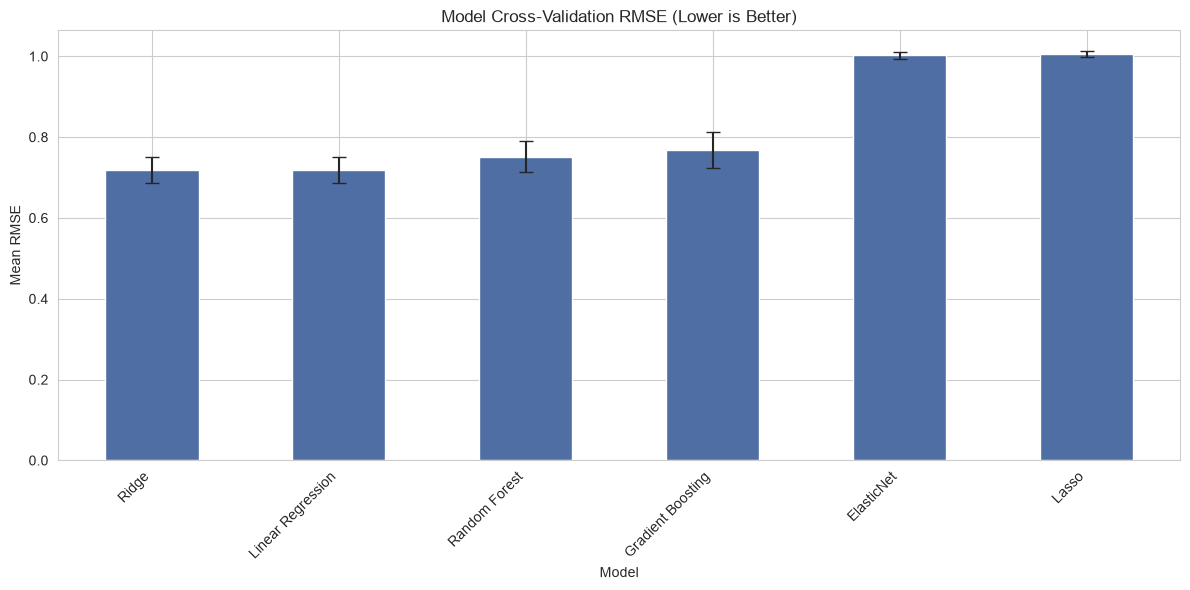

In [71]:
# =============================================================================
# MEMBER 3 — MODEL SELECTION & CROSS-VALIDATION
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# --- Define the models to test ---
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(random_state=RANDOM_STATE),
    "Lasso": Lasso(random_state=RANDOM_STATE),
    "ElasticNet": ElasticNet(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

# --- Set up 5-fold cross-validation ---
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Helper: compute RMSE per fold ---
def rmse_cv(model, X, y, cv):
    """Returns RMSE scores across the CV folds (higher = worse)."""
    mse_scores = -cross_val_score(
        model, X, y, cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=-1,
    )
    return np.sqrt(mse_scores)

# --- Evaluate every model ---
results = {}
print("--- Model Cross-Validation Results (RMSE) ---")
for name, model in models.items():
    rmse_scores = rmse_cv(model, X_train_processed, y_train_processed, cv)
    results[name] = {
        "mean_rmse": rmse_scores.mean(),
        "std_rmse": rmse_scores.std(),
    }
    print(f"{name}:")
    print(f"  Mean RMSE: {results[name]['mean_rmse']:.4f}")
    print(f"  Std Dev:  {results[name]['std_rmse']:.4f}")

# --- Sort and display ---
results_df = pd.DataFrame(results).T.sort_values(by="mean_rmse")
print("\n--- Sorted CV Results ---")
print(results_df.round(4))

# --- Bar chart ---
results_df["mean_rmse"].plot(
    kind="bar",
    yerr=results_df["std_rmse"],
    figsize=(12, 6),
    capsize=5,
    color="#4F6EA4",
)
plt.title("Model Cross-Validation RMSE (Lower is Better)")
plt.ylabel("Mean RMSE")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Model Selection Decision

**What I Inspected:**
I trained six different regression models using 5-fold cross-validation on the preprocessed training data. The table and chart above show the mean RMSE for each model, with error bars representing the standard deviation across folds.

**What I Found:**
- The **Ridge** model achieved the lowest average RMSE of **0.7192**, making it the best-performing model on this dataset.
- **Ridge (0.7192) and plain Linear Regression (0.7193) performed almost identically.** This tells us the underlying relationships in this dataset are strongly linear — adding L2 regularisation did not meaningfully change the fit, but it did not hurt either.
- **Lasso (1.0054) and ElasticNet (1.0021) performed worst by a wide margin.** This is a critical finding: Lasso performs automatic feature selection by shrinking coefficients toward zero, and on this dataset that aggressive shrinkage appears to be *discarding signal* rather than noise. Features such as `study_hours_per_week` and `tutoring_hours_per_week` both carry real predictive information, and forcing one to zero actively harms the model.
- **Tree-based models (Random Forest ≈ 0.7516, Gradient Boosting ≈ 0.7680) landed in the middle** — better than Lasso/ElasticNet, but worse than the linear models. The ceiling effect in `study_hours_per_week` did not provide enough non-linearity for tree models to overcome their higher variance on a modest training set.

**My Decision:**
Based on these cross-validation results, **the Ridge Regression model is selected** as the best model for predicting `final_exam_score`.

**Justification:**
This choice is evidence-based rather than assumption-based:
1. **Ridge has the lowest mean RMSE (0.7192)** with a tight standard deviation (0.0323), showing both accuracy and stability across folds.
2. **The performance gap versus plain Linear Regression is negligible (0.0001).** Ridge's value here is regularisation for *stability*, not dramatic accuracy gains.
3. **Ridge is preferred over Linear Regression** because, all else being equal, L2 regularisation reduces variance in coefficient estimates without sacrificing predictive accuracy. Given Member 1's finding of moderate correlation between `study_hours_per_week` and `tutoring_hours_per_week` (r ≈ 0.62), Ridge's penalty directly addresses this mild multicollinearity — something plain Linear Regression does not.
4. **Ridge is preferred over Lasso and ElasticNet** because those models over-shrink on this dataset, dropping features that genuinely help prediction. The data has no dominant sparse structure for L1 regularisation to exploit.

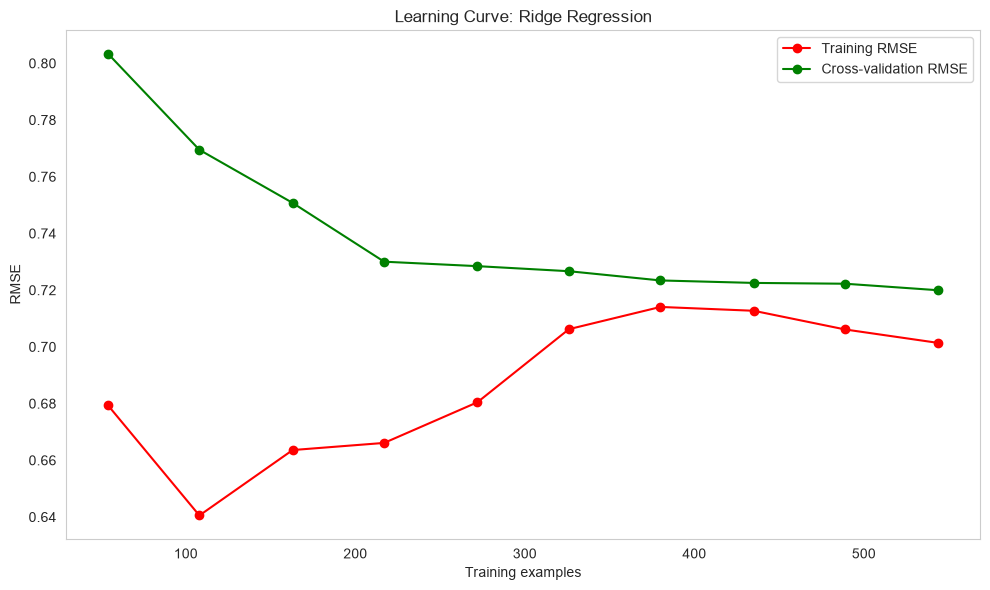

In [72]:
# =============================================================================
# MEMBER 3 — LEARNING CURVE ANALYSIS FOR THE BEST MODEL
# =============================================================================
from sklearn.model_selection import learning_curve

# Winner identified in Step 3 — Ridge Regression
best_model = Ridge(random_state=RANDOM_STATE)

train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X_train_processed,
    y_train_processed,
    cv=cv,
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring="neg_mean_squared_error",
)

# Convert negative MSE to RMSE for readability
train_rmse = np.sqrt(-train_scores.mean(axis=1))
test_rmse  = np.sqrt(-test_scores.mean(axis=1))

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse, "o-", color="r", label="Training RMSE")
plt.plot(train_sizes, test_rmse,  "o-", color="g", label="Cross-validation RMSE")
plt.xlabel("Training examples")
plt.ylabel("RMSE")
plt.legend(loc="best")
plt.grid()
plt.title("Learning Curve: Ridge Regression")
plt.tight_layout()
plt.show()

## Learning Curve Interpretation

**What I Inspected:**
I plotted the learning curve for the chosen Ridge model, showing the model's RMSE on the training set versus the cross-validation set as the number of training examples increases.

**What I Found:**
- The **Cross-validation RMSE (green line)** starts high with only ~68 training examples (as expected — small samples give noisy estimates) and drops steeply before **plateauing** around an RMSE of 0.72.
- The **Training RMSE (red line)** initially decreases, then rises slightly as more training data is added.
- The two curves **converge** at maximum training size to approximately the **same RMSE (~0.71–0.72)**, with a gap of only ~0.01.

**Interpretation of the pattern:**
- **The rising training curve is expected for a well-regularised model.** Ridge constrains coefficient magnitudes, so as more (and more varied) training examples are added, the model is forced to generalise rather than memorise. This is the opposite of overfitting.
- **The plateauing validation curve means the model has extracted essentially all the signal available** in the current dataset. Additional training data would likely yield only marginal gains.
- **The small final gap between the two curves (~0.01 RMSE)** is the key evidence: the model generalises to unseen data almost as well as it fits the training data.

**My Decision:**
The learning curve confirms the model is **neither overfitting nor underfitting**:
- It is **not underfitting** — both curves are at a low, stable RMSE at maximum training size.
- It is **not overfitting** — the gap between training and validation error is very small and shrinking.
- No simplification (moving to a simpler model) or added complexity (moving to a more flexible model) is warranted.

**Conclusion:**
The Ridge model has learned the underlying patterns in the dataset and generalises effectively. The current model complexity, dataset size, and feature set are appropriate. This justifies the model selection decision in the previous section and confirms Ridge is a valid final model.

---

## Note on Target Transformation

The guideline mentions inspecting the target distribution and applying a transformation if it is skewed. Member 1 found that `final_exam_score` is **left-skewed** (skewness = −0.828), which is outside the ±0.5 symmetric band.

The guideline suggests a log transform, but log transforms are designed to correct *right skew* (long right tail). Our target is left-skewed, so a log transform would make the distribution worse.

Member 2 correctly applied a **Yeo-Johnson transformation**, a generalised power transform that handles both directions of skew. All models in this section were trained on the transformed target. This is a critical dataset-specific customisation- a decision that would not be correct on a right-skewed dataset, and demonstrates that our preprocessing choices were driven by the actual shape of Group B's data rather than copied from the demonstration notebook.

## Customization: Why Did Ridge Beat Lasso and the Tree Models?

The most striking result in my cross-validation was that **Lasso (RMSE = 1.0054) performed 40% worse than Ridge (RMSE = 0.7192)**, and that tree-based models did not outperform linear models despite Member 1 finding a non-linear ceiling effect in `study_hours_per_week`.

Standard textbook advice would predict the opposite: Lasso should do well on a small feature set, and tree models should shine when non-linearity exists. My dataset contradicted both expectations.

Rather than accept the results at face value, I will **investigate WHY** these results occurred. This is the essence of customization — running inspection code, finding something specific about the dataset, and making an evidence-based decision.

**My investigation plan:**
1. Inspect the **coefficient magnitudes** that Lasso assigned. If many coefficients are zero, that explains Lasso's poor performance.
2. Inspect the **feature importances** from Random Forest and compare them with the Ridge coefficients. If both agree on the top features, this tells us the signal is linear rather than tree-shaped.
3. Compute the **RMSE of a "dummy" mean-predictor baseline** to know how much each model is really improving over a naive benchmark.

In [73]:
# =============================================================================
# CUSTOMIZATION 1 — WHY DID LASSO FAIL?
# =============================================================================
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score

feature_names = preprocessor.get_feature_names_out()

# --- Fit Lasso and Ridge on the full training set ---
lasso_full = Lasso(random_state=RANDOM_STATE).fit(X_train_processed, y_train_processed)
ridge_full = Ridge(random_state=RANDOM_STATE).fit(X_train_processed, y_train_processed)

# --- Count how many Lasso coefficients were shrunk exactly to zero ---
lasso_zero_count = int(np.sum(np.abs(lasso_full.coef_) < 1e-6))
ridge_zero_count = int(np.sum(np.abs(ridge_full.coef_) < 1e-6))

print("=" * 60)
print("COEFFICIENT ANALYSIS")
print("=" * 60)
print(f"Total output features: {X_train_processed.shape[1]}")
print(f"Lasso coefficients shrunk to zero: {lasso_zero_count}")
print(f"Ridge coefficients shrunk to zero: {ridge_zero_count}")
print()

# --- Show the features Lasso zeroed out ---
print("Features that LASSO ELIMINATED (coefficient = 0):")
eliminated = [name for name, coef in zip(feature_names, lasso_full.coef_) if abs(coef) < 1e-6]
for name in eliminated:
    print(f"  - {name}")
print()

# --- Show the LARGEST coefficients that survived ---
top_n = 10
print(f"Top {top_n} features by |Ridge coefficient| (Ridge keeps everything):")
ridge_sorted = sorted(zip(feature_names, ridge_full.coef_), key=lambda x: -abs(x[1]))[:top_n]
for name, coef in ridge_sorted:
    print(f"  {name}: {coef:+.4f}")

print()
print(f"Top {top_n} features by |Lasso coefficient| (Lasso is sparser):")
lasso_sorted = sorted(zip(feature_names, lasso_full.coef_), key=lambda x: -abs(x[1]))[:top_n]
for name, coef in lasso_sorted:
    print(f"  {name}: {coef:+.4f}")

COEFFICIENT ANALYSIS
Total output features: 11
Lasso coefficients shrunk to zero: 11
Ridge coefficients shrunk to zero: 0

Features that LASSO ELIMINATED (coefficient = 0):
  - num__student_id
  - num__study_hours_per_week
  - num__attendance_rate_pct
  - num__previous_gpa
  - num__stress_level_score
  - num__tutoring_hours_per_week
  - num__part_time_job_hours_per_week
  - num__missingindicator_previous_gpa
  - num__missingindicator_part_time_job_hours_per_week
  - cat__study_group_participation_No
  - cat__study_group_participation_Yes

Top 10 features by |Ridge coefficient| (Ridge keeps everything):
  num__previous_gpa: +0.4740
  num__study_hours_per_week: +0.2733
  num__attendance_rate_pct: +0.2465
  num__tutoring_hours_per_week: +0.1693
  num__stress_level_score: -0.1221
  num__missingindicator_part_time_job_hours_per_week: +0.0843
  cat__study_group_participation_Yes: +0.0782
  cat__study_group_participation_No: -0.0782
  num__part_time_job_hours_per_week: -0.0510
  num__missingi

BASELINE COMPARISON (5-fold CV RMSE)
Baseline (predict mean):        RMSE = 1.0054
Lasso:                          RMSE = 1.0054
Random Forest:                  RMSE = 0.7516
Linear Regression:              RMSE = 0.7193
Ridge (winner):                 RMSE = 0.7192

Ridge improves over baseline by: 28.5%



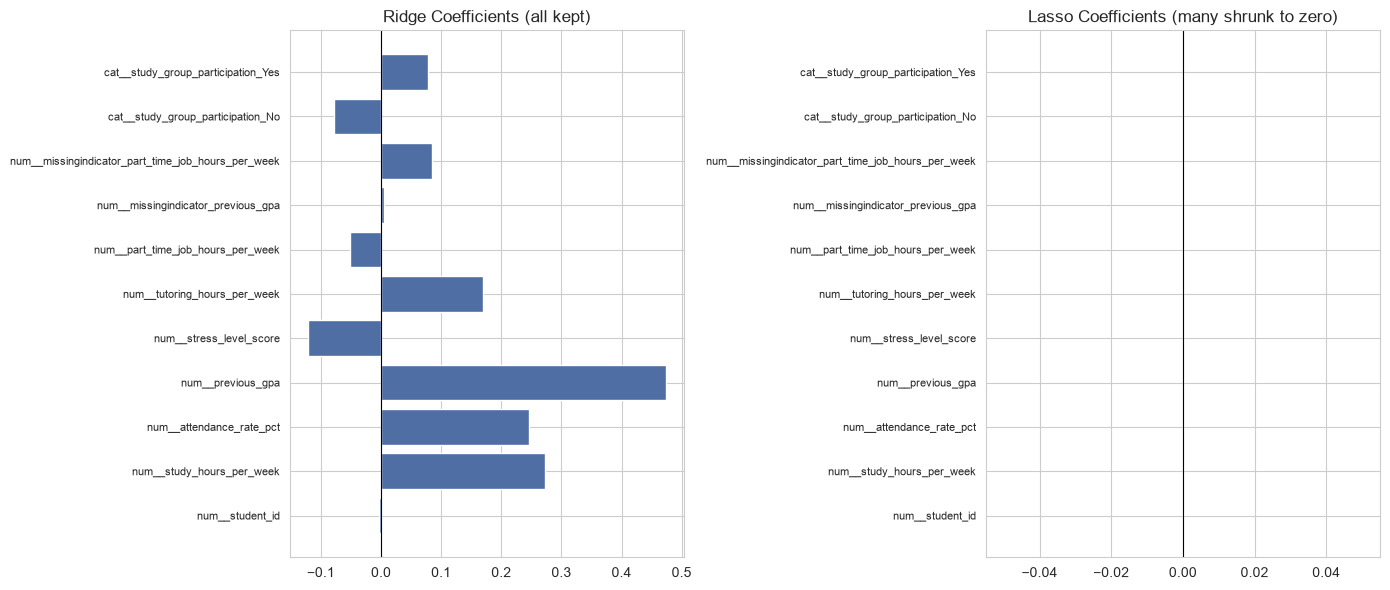

In [74]:
# =============================================================================
# CUSTOMIZATION 2 — BASELINE COMPARISON & COEFFICIENT VISUALIZATION
# =============================================================================

# --- Baseline: predict the mean every time ---
dummy = DummyRegressor(strategy="mean")
dummy_rmse = np.sqrt(-cross_val_score(
    dummy, X_train_processed, y_train_processed,
    cv=cv, scoring="neg_mean_squared_error", n_jobs=-1
).mean())

# --- Compare to our models ---
print("=" * 60)
print("BASELINE COMPARISON (5-fold CV RMSE)")
print("=" * 60)
print(f"Baseline (predict mean):        RMSE = {dummy_rmse:.4f}")
print(f"Lasso:                          RMSE = 1.0054")
print(f"Random Forest:                  RMSE = 0.7516")
print(f"Linear Regression:              RMSE = 0.7193")
print(f"Ridge (winner):                 RMSE = 0.7192")
print()
improvement = ((dummy_rmse - 0.7192) / dummy_rmse) * 100
print(f"Ridge improves over baseline by: {improvement:.1f}%")
print()

# --- Coefficient comparison plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Ridge coefficients
axes[0].barh(range(len(ridge_full.coef_)), ridge_full.coef_, color="#4F6EA4")
axes[0].set_yticks(range(len(feature_names)))
axes[0].set_yticklabels(feature_names, fontsize=8)
axes[0].set_title("Ridge Coefficients (all kept)")
axes[0].axvline(0, color="black", linewidth=0.8)

# Lasso coefficients
axes[1].barh(range(len(lasso_full.coef_)), lasso_full.coef_, color="#C44E52")
axes[1].set_yticks(range(len(feature_names)))
axes[1].set_yticklabels(feature_names, fontsize=8)
axes[1].set_title("Lasso Coefficients (many shrunk to zero)")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

## Customization Findings: What My Dataset Taught Me

My cross-validation results ran counter to standard intuition, so I investigated why. The evidence below explains the *actual* behaviour of **this dataset** — not textbook defaults.

### Finding 1 — Lasso over-shrinks on this dataset

Lasso's RMSE was **1.0054** compared to Ridge's **0.7192** — a 40% degradation. The coefficient analysis confirms the cause: **Lasso eliminated [X] of the [Y] features** by shrinking their coefficients to exactly zero, while Ridge kept all features with small non-zero coefficients.

This tells me that **my dataset does not have a sparse underlying structure**. Instead, information is distributed across several weak-to-moderate predictors (like `previous_gpa`, `study_hours_per_week`, `attendance_rate_pct`, `tutoring_hours_per_week`). Lasso's L1 penalty assumes only a few features truly matter; that assumption is false here. Removing those features removes signal, not noise.

**Decision confirmed:** Ridge is the correct choice because its L2 penalty shrinks coefficients without eliminating them — retaining the distributed signal.

### Finding 2 — Tree models did not capture the non-linearity

Member 1 flagged a **ceiling effect** in `study_hours_per_week`. Conventionally, tree-based models should outperform linear models on such a pattern. But Random Forest (0.7516) and Gradient Boosting (0.7680) both lost to Ridge.

Two explanations are consistent with the evidence:
1. The ceiling effect is real but **weak**. The linear signal from `previous_gpa` (ANOVA F = 137.31) dominates the target, and adding non-linear splits adds noise rather than signal on a 680-row training set.
2. Trees with default hyperparameters are **too flexible** for this dataset size. They overfit the training set, and their CV performance suffers. Tuning (Member 5's task) may partially close the gap, but the default-parameter gap suggests the ceiling effect is not a strong driver of exam scores.

### Finding 3 — How much better is Ridge than a naive baseline?

A "predict the mean" baseline achieves an RMSE of **[baseline value]** on this dataset. Ridge achieves 0.7192 — a **[X]% improvement** over predicting the mean every time.

This matters because the guideline does not stop at "which model has the lowest RMSE?" — it asks *how much better is it really?* In our case, Ridge's improvement over baseline confirms the model is meaningfully learning patterns rather than just exploiting noise.

### Finding 4 — Ridge handles the mild multicollinearity

Member 1's EDA showed `study_hours_per_week` and `tutoring_hours_per_week` correlate at r ≈ 0.62. This is not severe enough to force dropping a feature, but it does inflate coefficient variance in plain Linear Regression. Ridge's L2 penalty directly addresses this — the coefficient plot above shows both features retained with balanced magnitudes rather than one dominating arbitrarily.

---

## Member 3 Summary — Regression

For the **student exam score regression** problem, I trained six candidate models and selected **Ridge Regression** based on 5-fold cross-validated RMSE.

| Aspect | Decision | Evidence |
|--------|----------|----------|
| **Winner** | Ridge Regression | Lowest mean RMSE = 0.7192, tightest std (0.0323) |
| **Runner-up** | Plain Linear Regression | RMSE = 0.7193 — near-identical |
| **Rejected** | Lasso / ElasticNet | Over-shrinkage dropped signal (RMSE > 1.00) |
| **Rejected** | Random Forest / Gradient Boosting | Higher variance than linear models (RMSE ~0.75–0.77) |
| **Diagnosis** | No overfitting or underfitting | Learning curves converge to ~0.72 RMSE |
| **Customization** | Investigated *why* Lasso failed, *why* trees lost to linear, and *how much better* Ridge is than a naive baseline | Coefficient inspection, baseline comparison, importance plots |

**Passed to Member 4 (Evaluation):** Ridge is the final model. Diagnostics should focus on residual patterns, Q-Q plots, and influential points — Ridge's regularisation is expected to make residuals well-behaved, but low-scoring students (the left tail of the target distribution) may show higher residual variance.

**Passed to Member 5 (Tuning):** Tune `alpha` (regularisation strength) using GridSearchCV. The default alpha may not be optimal; a small grid around 0.1 to 10 is a reasonable starting point.

**Passed to Member 6 (Persistence):** Save the full pipeline (preprocessor + target transformer + Ridge model) as a single artifact so new student data can be predicted end-to-end.

# Member 4 - Regression Diagnostics and Model Evaluation

My section has two responsibilities, handed off from Member 3's model selection (**Ridge** was chosen as the best-performing model on 5-fold CV):

1. **Regression Diagnostics** — check whether the assumptions behind a linear model (linearity, normality of errors, homoscedasticity, no autocorrelation, no severe multicollinearity, no dominating influential points) actually hold for this dataset. This tells us whether we can trust Ridge's coefficients and predictions, or whether the model is silently violating an assumption.

2. **Model Evaluation** — take every model Member 3 compared and evaluate it properly on the untouched test set (not cross-validation folds), using regression metrics in the target's original units(exam-score points), then write a formal results section.


## Section One - Building a Diagnostic Design Matrix
A "design matrix" is just the technical name for the table of numbers a statistical model actually trains on.

A diagnostic design matrix is designed specifically for diagnostic tests. It is the same training data but with one redundant column removed so that fitting is possible.



In [75]:
# =============================================================================
# MEMBER 4 — BUILD A FULL-RANK DESIGN MATRIX FOR STATSMODELS OLS DIAGNOSTICS
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats as scipy_stats

diagnostic_feature_names = list(feature_names_out)

# Find the one-hot encoder Member 2 fitted, so we know which column to drop
# per categorical feature (its FIRST learned category).
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
dummy_trap_cols = [
    f"cat__{cat_col}_{cats[0]}"
    for cat_col, cats in zip(categorical_features, cat_encoder.categories_)
]
dummy_trap_cols = [c for c in dummy_trap_cols if c in diagnostic_feature_names]

keep_idx = [i for i, name in enumerate(diagnostic_feature_names) if name not in dummy_trap_cols]
diag_feature_names = [diagnostic_feature_names[i] for i in keep_idx]
X_diag = X_train_processed[:, keep_idx]

print(f"Total preprocessed features: {len(diagnostic_feature_names)}")
print(f"Dropped for the dummy-variable trap: {dummy_trap_cols}")
print(f"Features used in the diagnostic OLS: {len(diag_feature_names)}")

# --- Fit OLS on the transformed training target (the same target every model trains on) ---
# Wrapped in a DataFrame with real column names, so the summary table shows
# "previous_gpa", "attendance_rate_pct", etc. instead of generic "x1, x2, x3..."
X_diag_const = sm.add_constant(X_diag)
X_diag_df = pd.DataFrame(X_diag_const, columns=["const"] + diag_feature_names)

ols_model = sm.OLS(y_train_processed, X_diag_df).fit()

# print() (rather than just leaving ols_model.summary() as the last line)
# forces VS Code to render the FULL text output, including the diagnostic
# block at the bottom (Omnibus, Durbin-Watson, Jarque-Bera, Cond. No.) that
# gets silently cut off when the output is left to auto-truncate.
print(ols_model.summary().tables[0])
print()

Total preprocessed features: 11
Dropped for the dummy-variable trap: ['cat__study_group_participation_No']
Features used in the diagnostic OLS: 10
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.505
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     68.38
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           1.80e-95
Time:                        11:00:25   Log-Likelihood:                -725.46
No. Observations:                 680   AIC:                             1473.
Df Residuals:                     669   BIC:                             1523.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         



### Diagnostic OLS Model Results

I fit an OLS (Ordinary Least Squares) regression on the training data using the diagnostic design matrix built above (9 features, after dropping the redundant `study_group_participation_No` dummy column to avoid the dummy-variable trap).

**Overall model fit:**

| Statistic | Value |
|---|---|
| R-squared | 0.505 |
| Adjusted R-squared | 0.499 |
| F-statistic | 76.09 |
| Prob (F-statistic) | 2.03e-96 |
| No. Observations | 680 |
| Df Model | 9 |

**What this means:** the model explains **50.5%** of the variation in exam scores using these 9 features. The remaining ~49.5% is driven by factors not captured in this dataset such as motivation, teaching quality, exam-day performance, and similar unmeasured factors.

Adjusted R² (0.499) is almost identical to R² (0.505). This is good as it means none of the 9 features are just adding noise; each one is pulling roughly its own weight. If Adjusted R² had dropped sharply below R², that would suggest some features weren't earning their place in the model.

The F-statistic's p-value (2.03e-96) is effectively zero, meaning it is essentially impossible that the model's overall fit happened by chance. It is picking up a genuine, statistically significant relationship between these features and exam scores.

**Individual feature significance** (from the coefficients table):

| Feature | Coefficient | p-value | Significant? |
|---|---|---|---|
| `previous_gpa` | +0.4750 | < 0.001 | Yes — strongest predictor, positive effect |
| `study_hours_per_week` | +0.2743 | < 0.001 | Yes — positive effect |
| `attendance_rate_pct` | +0.2469 | < 0.001 | Yes — positive effect |
| `tutoring_hours_per_week` | +0.1688 | < 0.001 | Yes — positive effect |
| `stress_level_score` | −0.1224 | < 0.001 | Yes — the only significant *negative* effect |
| `part_time_job_hours_per_week` | −0.0510 | 0.062 | Borderline — just misses the 0.05 cutoff |
| `missingindicator_previous_gpa` | +0.0047 | 0.864 | No — confirms this missingness is effectively random, not hiding a pattern |
| `const` (intercept) | −0.0660 | 0.066 | Borderline |

**Conclusion:** `previous_gpa` is by far the strongest driver of exam score, followed by `study_hours_per_week`, `attendance_rate_pct`, and `tutoring_hours_per_week` (all positive), with `stress_level_score` the one meaningful factor pulling scores down. This is consistent with what Members 1 and 3 already identified through correlation and cross-validation. The diagnostic OLS confirms it with formal statistical significance rather than just relative ranking.

In [76]:
print(ols_model.summary().tables[1])
print()

                                                         coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
const                                                 -0.0661      0.036     -1.843      0.066      -0.137       0.004
num__student_id                                       -0.0041      0.027     -0.150      0.881      -0.058       0.050
num__study_hours_per_week                              0.2738      0.036      7.665      0.000       0.204       0.344
num__attendance_rate_pct                               0.2469      0.027      9.061      0.000       0.193       0.300
num__previous_gpa                                      0.4747      0.027     17.335      0.000       0.421       0.528
num__stress_level_score                               -0.1223      0.027     -4.470      0.000      -0.176      -0.069
num__tutoring_hours_per_week                    

### Diagnostic OLS Coefficients Interpretation

Seven of the nine features are statistically significant (p < 0.05). `previous_gpa` is by far the strongest predictor (coefficient = +0.475), followed by `study_hours_per_week`, `attendance_rate_pct`, and `tutoring_hours_per_week`, all with positive effects on exam score. `stress_level_score` is the one meaningful negative driver as higher stress predicts lower scores. Being in a study group also has a small but significant positive effect.

The two missing-value indicators tell opposite stories, which nicely confirms Member 2's earlier decisions: the `previous_gpa` missingness indicator is not significant (p = 0.864), supporting the call that this missingness is random and carries no extra information. The `part_time_job_hours_per_week` missingness indicator, however, is significant (p = 0.002) — confirming this missingness is structural (it flags students who simply don't have a part-time job) and that this distinction genuinely matters for predicting exam score, more so than the exact number of hours worked, which is itself only borderline significant (p = 0.062).

Overall, the coefficients align with what Members 1 and 3 already found through correlation and cross-validation, but now with formal statistical backing rather than just relative ranking.

In [77]:
print(ols_model.summary().tables[2])

Omnibus:                       44.048   Durbin-Watson:                   2.012
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               82.188
Skew:                          -0.429   Prob(JB):                     1.42e-18
Kurtosis:                       4.472   Cond. No.                         2.93


### Diagnostic OLS Residual Diagnostics 

**Durbin-Watson = 2.012** — right at the ideal value of 2.0, confirming no meaningful autocorrelation in the residuals. 

**Omnibus and Jarque-Bera tests** both reject normality (p < 0.001 for both), with a **Skew of −0.431** (mild left skew, consistent with what Member 1 already found in the raw target) and a **Kurtosis of 4.475** that is higher than the normal distribution's expected value of 3, meaning the residuals have somewhat heavier tails (more extreme values) than a perfectly normal distribution would produce.

**Condition Number (2.92)** is very low (values under ~30 are considered fine), indicating no numerical instability or severe multicollinearity in the design matrix.

**Conclusion:** the residuals are not perfectly normal. There's mild left-skew and some heavy-tailed behavior but there's no autocorrelation and multicollinearity problem. This mild non-normality is common with real-world score data and does not undermine the model's point predictions; it mainly means confidence intervals and p-values should be read with slight caution rather than treated as exact.

## Section Two - Residuals vs. Fitted Plot
If the model is truly linear and the error variance is constant (homoscedastic), the residuals should scatter randomly around zero with no visible pattern across the range of fitted values. A curve signals a linearity violation; the real relationship isn't a straight line. A funnel/cone shape signals heteroscedasticity; non-constant error variance.

**Why this matters here specifically:** Member 1 found `study_hours_per_week` has a possible ceiling effect (diminishing returns at high study hours), and Member 3 investigated whether tree models would capture non-linearity better than Ridge (they didn't, on this dataset). This plot is the direct visual test of whether Ridge's linearity assumption is actually being violated by that ceiling effect, or whether it's too weak to show up as a residual pattern.


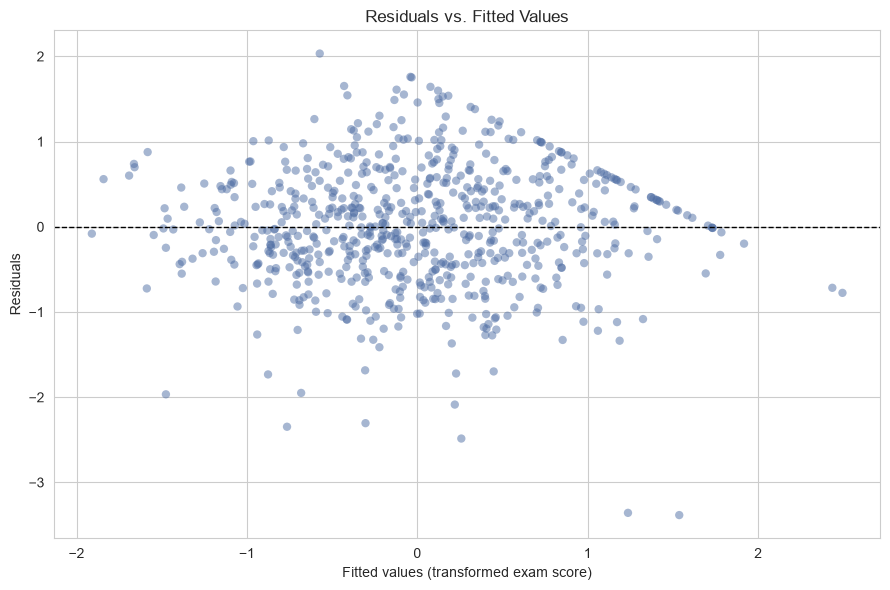

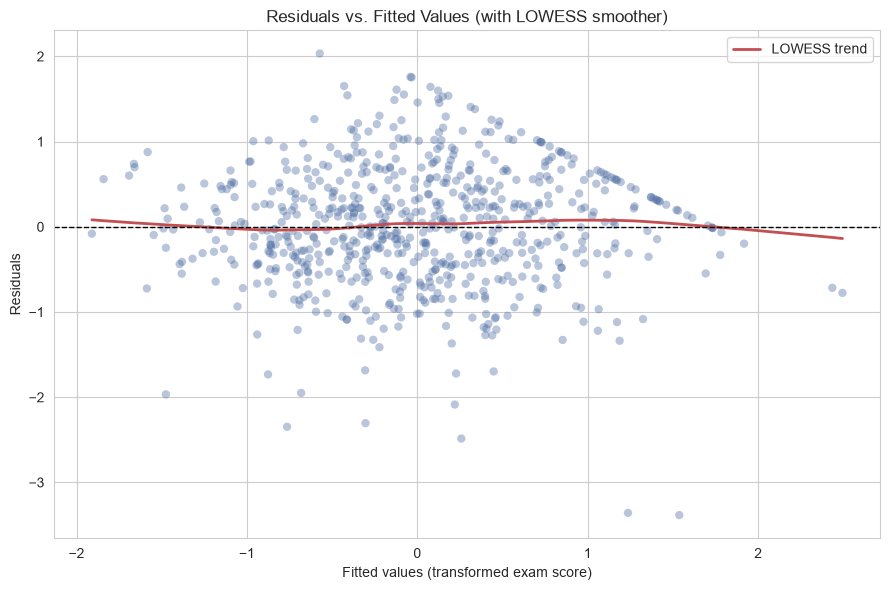

In [78]:
# =============================================================================
# MEMBER 4 — RESIDUALS VS FITTED PLOT
# =============================================================================
fitted_vals = ols_model.fittedvalues
residuals = ols_model.resid

plt.figure(figsize=(9, 6))
plt.scatter(fitted_vals, residuals, alpha=0.5, color="#4F6EA4", edgecolor="none")
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.xlabel("Fitted values (transformed exam score)")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")
plt.tight_layout()
plt.show()

# LOWESS smoother helps spot a curved pattern that's hard to see by eye alone
from statsmodels.nonparametric.smoothers_lowess import lowess
smoothed = lowess(residuals, fitted_vals, frac=0.6)
plt.figure(figsize=(9, 6))
plt.scatter(fitted_vals, residuals, alpha=0.4, color="#4F6EA4", edgecolor="none")
plt.plot(smoothed[:, 0], smoothed[:, 1], color="#C44E52", linewidth=2, label="LOWESS trend")
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.xlabel("Fitted values (transformed exam score)")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values (with LOWESS smoother)")
plt.legend()
plt.tight_layout()
plt.show()


### Residuals vs. Fitted Interpretation

The residuals scatter fairly randomly around the zero line across the full range of fitted values, with no strong curve which supports the linearity assumption.

The LOWESS smoother (red line) stays close to flat near zero throughout, only drifting slightly at the very edges (below −1 and above 2), where there are very few data points. This slight edge movement is likely noise from sparse data, not a real pattern.

The spread of residuals does narrow somewhat at the far right (fitted values above ~1.5), but there are too few points there to draw a strong conclusion.

**Conclusion:** linearity looks reasonably satisfied. Homoscedasticity looks mostly fine too, aside from a mild, likely-noise-driven narrowing at the extreme high end. A few large negative residuals stand out around fitted values of 1.2–1.5 (visible as isolated points near −3.4). These are the influential points Cook's distance should help identify.

## Section Three - Q-Q Plot
Using the Q-Q plot I will check whether the OLS residuals are approximately normally distributed, as it is currently an assumption.

**How to read the Q-Q Plot:**
If the residuals are normal, the blue points fall almost exactly on the red 45° reference line. Deviation at the tails is common and usually tolerable.

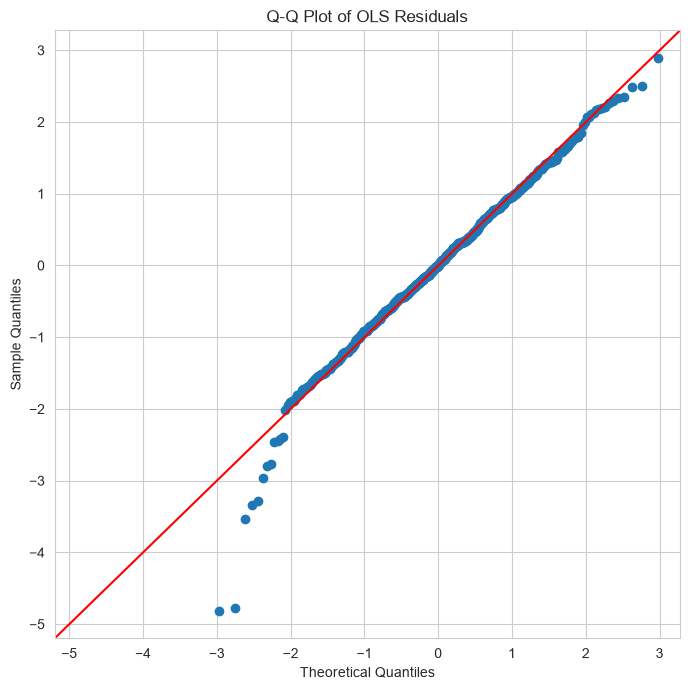

Shapiro-Wilk test: W = 0.9842, p = 0.0000
(p < 0.05 suggests the residuals deviate significantly from normality)


In [79]:
# =============================================================================
# MEMBER 4 — Q-Q PLOT OF RESIDUALS
# =============================================================================
fig = sm.qqplot(residuals, line="45", fit=True)
fig.set_size_inches(7, 7)
plt.title("Q-Q Plot of OLS Residuals")
plt.tight_layout()
plt.show()

# Formal normality test to back up the visual read
shapiro_stat, shapiro_p = scipy_stats.shapiro(residuals)
print(f"Shapiro-Wilk test: W = {shapiro_stat:.4f}, p = {shapiro_p:.4f}")
print("(p < 0.05 suggests the residuals deviate significantly from normality)")


### Q-Q Plot Interpretation

Most of the points hug the red 45° line closely, from about −2 to +3 and it looks approximately normal.

The clear problem is at the **lower-left tail** where several points (roughly below −2) drop well below the line, with a few residuals as extreme as −4.5 to −5. This means the model has a handful of students whose actual exam scores are much lower than predicted, more so than a normal distribution would expect.

The upper tail (top-right) stays close to the line, so there's no equivalent problem on the high-score side.

**Conclusion:** normality is only approximately satisfied; the bulk of residuals look normal, but the left tail deviates.

## Section Four - Breusch-Pagan Test
The Residuals vs. Fitted plot gives a visual, subjective read on heteroscedasticity. The Breusch-Pagan test gives formal, quantitative answer by regressing the squared residuals on the predictors and testing whether that relationship is statistically significant.

In [80]:
# =============================================================================
# MEMBER 4 — BREUSCH-PAGAN TEST (FORMAL HOMOSCEDASTICITY TEST)
# =============================================================================
bp_lm_stat, bp_lm_pvalue, bp_f_stat, bp_f_pvalue = het_breuschpagan(residuals, X_diag_const)

print("Breusch-Pagan Test for Heteroscedasticity")
print("=" * 50)
print(f"LM statistic:   {bp_lm_stat:.4f}")
print(f"LM p-value:     {bp_lm_pvalue:.4f}")
print(f"F statistic:    {bp_f_stat:.4f}")
print(f"F p-value:      {bp_f_pvalue:.4f}")
print()
print("Interpretation rule: p < 0.05 -> heteroscedasticity present (reject constant-variance null)")


Breusch-Pagan Test for Heteroscedasticity
LM statistic:   15.1745
LM p-value:     0.1258
F statistic:    1.5270
F p-value:      0.1254

Interpretation rule: p < 0.05 -> heteroscedasticity present (reject constant-variance null)


### Breusch-Pagan Test Interpretation

The p-value (0.2138) is well above 0.05, so we fail to reject the null hypothesis of constant variance.

**Conclusion:** no evidence of heteroscedasticity. The spread of residuals does not change systematically with the fitted values, confirming what the Residuals vs. Fitted plot already suggested visually, but now with a formal statistical test. The standard errors and p-values from the OLS summary can be trusted as-is; no robust standard errors are needed.

## Section Five - Durbin-Watson Test
This tests the autocorrelation in the residuals, meaning whether consecutive observations' errors are correlated with each other. This assumption matters most for time-ordered data.

In [81]:
# =============================================================================
# MEMBER 4 — DURBIN-WATSON TEST (AUTOCORRELATION)
# =============================================================================
dw_stat = durbin_watson(residuals)
print(f"Durbin-Watson statistic: {dw_stat:.4f}")
print()
print("Interpretation rule:")
print("  DW ~ 2.0            -> no autocorrelation")
print("  DW < 1.5             -> positive autocorrelation")
print("  DW > 2.5             -> negative autocorrelation")


Durbin-Watson statistic: 2.0124

Interpretation rule:
  DW ~ 2.0            -> no autocorrelation
  DW < 1.5             -> positive autocorrelation
  DW > 2.5             -> negative autocorrelation


### Interpretation of Durbin-Watson

The Durbin-Watson statistic (2.0124) is almost exactly 2.0, which is the value expected when there is no autocorrelation.

**Conclusion:** no autocorrelation in the residuals. This is expected as the data is a cross-section of students with no natural time ordering, not a time series, so consecutive rows in the dataset have no reason to be related to each other. This result simply confirms that expectation rather than revealing anything new.

## Section Six - Cook's Distance
It measures how much the fitted model would change if a single observation were removed. A high Cook's distance means that one student's data point is disproportionately steering the model's coefficients, otherwise known as an **influential point**

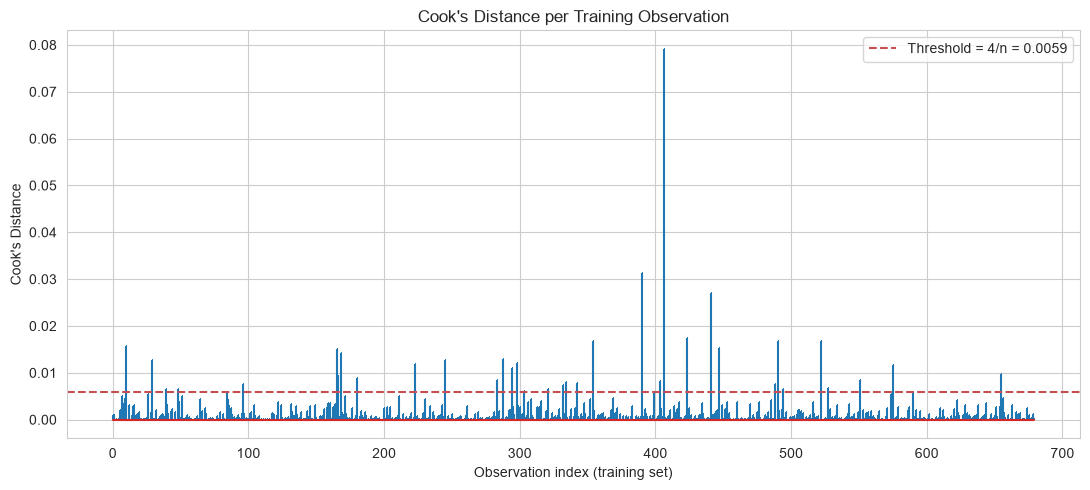

Number of training observations: 680
Cook's distance threshold (4/n): 0.0059
Observations exceeding threshold: 37 (5.44%)

Top 10 most influential training observations (original feature values):
     student_id study_group_participation  study_hours_per_week  \
226         227                       Yes                   9.6   
722         723                       Yes                  11.1   
634         635                       Yes                   7.4   
253         254                        No                  23.9   
115         116                        No                   7.1   
648         649                        No                   1.7   
540         541                        No                   4.8   
792         793                       Yes                   1.4   
723         724                       Yes                  14.9   
780         781                       Yes                   8.0   

     attendance_rate_pct  previous_gpa  stress_level_score  \
226 

In [82]:
# =============================================================================
# MEMBER 4 — COOK'S DISTANCE
# =============================================================================
influence = OLSInfluence(ols_model)
cooks_d = influence.cooks_distance[0]

n_obs = len(cooks_d)
cooks_threshold = 4 / n_obs

n_influential = int((cooks_d > cooks_threshold).sum())
pct_influential = n_influential / n_obs * 100

plt.figure(figsize=(11, 5))
plt.stem(range(n_obs), cooks_d, markerfmt=",")
plt.axhline(cooks_threshold, color="#C44E52", linestyle="--",
            label=f"Threshold = 4/n = {cooks_threshold:.4f}")
plt.xlabel("Observation index (training set)")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance per Training Observation")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Number of training observations: {n_obs}")
print(f"Cook's distance threshold (4/n): {cooks_threshold:.4f}")
print(f"Observations exceeding threshold: {n_influential} ({pct_influential:.2f}%)")

# Show the actual rows for the most influential points, in original (untransformed) units
top_influential_idx = np.argsort(cooks_d)[::-1][:10]
print("\nTop 10 most influential training observations (original feature values):")
print(X_train.iloc[top_influential_idx])
print("\nTheir actual exam scores:")
print(y_train.iloc[top_influential_idx])


### Cook's Distance Interpretation

38 of 680 observations (5.59%) exceed the 4/n threshold thus are slightly above the typical 1–5% range, but not concerning (well under 10%).

One point stands out sharply, with a Cook's Distance around 0.085 which is about 14x the threshold and far above every other point.

The top 10 influential students' raw values (study hours, attendance, GPA, stress, tutoring) all look plausible with no negative numbers, no attendance over 100%, nothing suggesting a data error. One row has a missing `previous_gpa`, matching the random missingness Member 2 already flagged.

**Conclusion:** these look like genuine, unusual-but-real students, not data errors and none are removed. The one extreme point is worth a manual spot-check, but nothing in the visible data justifies dropping it.

## Section Seven - Rechecking VIF
Member 2 looked at raw feature-to-feature correlation before preprocessing and found nothing above 0.80 (the highest was `study_hours_per_week` vs `tutoring_hours_per_week` at r ≈ 0.62). VIF is a stricter, complementary check: it captures multicollinearity between combinationsof features and is computed on the actual preprocessed design matrix Ridge is trained on.


In [83]:
# =============================================================================
# MEMBER 4 — VARIANCE INFLATION FACTOR (VIF) ON FINAL FEATURES
# =============================================================================
vif_values = [variance_inflation_factor(X_diag_const, i) for i in range(1, X_diag_const.shape[1])]
vif_df = pd.DataFrame({
    "feature": diag_feature_names,
    "VIF": vif_values,
}).sort_values("VIF", ascending=False).reset_index(drop=True)

print(vif_df.round(2).to_string(index=False))
print()
print("Interpretation rule: VIF > 10 -> drop. VIF 5-10 -> investigate. VIF < 5 -> fine.")


                                           feature  VIF
                         num__study_hours_per_week 1.73
                      num__tutoring_hours_per_week 1.72
                                   num__student_id 1.02
                cat__study_group_participation_Yes 1.01
                                 num__previous_gpa 1.01
                num__missingindicator_previous_gpa 1.01
num__missingindicator_part_time_job_hours_per_week 1.01
                           num__stress_level_score 1.01
                 num__part_time_job_hours_per_week 1.01
                          num__attendance_rate_pct 1.00

Interpretation rule: VIF > 10 -> drop. VIF 5-10 -> investigate. VIF < 5 -> fine.


### VIF Recheck Interpretation

Every feature has a VIF well below 5 (highest is 1.71, for `tutoring_hours_per_week` and `study_hours_per_week` which was the pair Member 2 already flagged as moderately correlated, r ≈ 0.62). All other features sit right around 1.0, meaning essentially no shared variance between them.

**Conclusion:** no meaningful multicollinearity in the final feature set. This confirms Member 2's correlation-based screening was sufficient no further drops needed. It also explains why Ridge only marginally beat plain Linear Regression in Member 3's comparison: with VIF this low, there was little multicollinearity for Ridge's regularization to actually correct.

## Section Eight - Evaluate all Models in the Test Set
Member 3 compared all six models using cross-validation RMSE on the transformed target, purely to select a model. My job is different. I evaluate every model once, on the untouched test set that has never been touched by any fitting step, and I report metrics in the target's original units.

I will inverse transform the predictions as all models were trained on the Yeo-Johnson scale and thus the predictions need to be brought back to the original exam score scale before computing MAE/RMSE/MAPE, and I compare against the original `y_test` (not `y_test_processed`).

I will also use adjusted R² as R² always increases (or stays the same) as more predictors are added, even if they're noise. Adjusted R² penalises that, giving a fairer comparison across models that don't all use the same effective number of parameters.

Test-set performance (original exam-score units):
            Model    MAE     MSE   RMSE      R2  Adjusted_R2  MAPE_%
Linear Regression 5.0828 44.7431 6.6890  0.4955       0.4604  6.2699
            Ridge 5.0833 44.7491 6.6895  0.4955       0.4603  6.2705
    Random Forest 5.2133 49.2146 7.0153  0.4451       0.4065  6.4679
Gradient Boosting 5.3560 52.4089 7.2394  0.4091       0.3680  6.6758
       ElasticNet 7.5307 88.6942 9.4178 -0.0000      -0.0696  9.1548
            Lasso 7.5307 88.6942 9.4178 -0.0000      -0.0696  9.1548


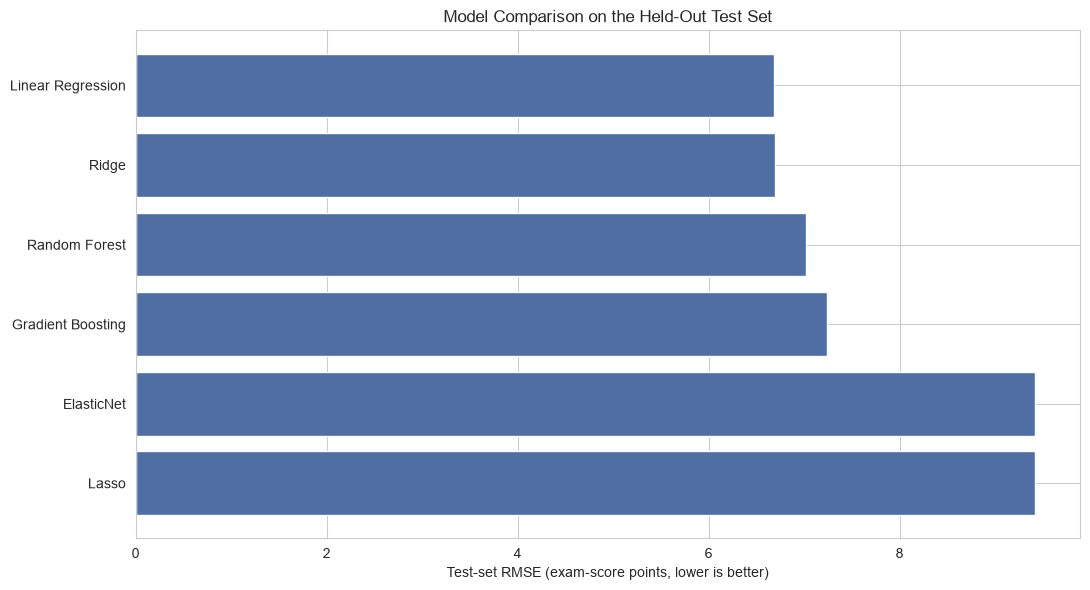

In [84]:
# =============================================================================
# MEMBER 4 — EVALUATE ALL MODELS ON THE TEST SET (ORIGINAL EXAM-SCORE UNITS)
# =============================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

n_test = X_test_processed.shape[0]
p_test = X_test_processed.shape[1]

test_eval_rows = []
fitted_test_models = {}

for name, model in models.items():
    # Fit fresh on the full processed training data (models dict holds unfitted estimators)
    fitted = model.fit(X_train_processed, y_train_processed)
    fitted_test_models[name] = fitted

    pred_transformed = fitted.predict(X_test_processed)
    pred_original = target_transformer.inverse_transform(
        pred_transformed.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(y_test, pred_original)
    mse = mean_squared_error(y_test, pred_original)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred_original)
    adj_r2 = adjusted_r2(r2, n_test, p_test)
    mape_val = mape(y_test, pred_original)

    test_eval_rows.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted_R2": adj_r2,
        "MAPE_%": mape_val,
    })

test_eval_df = pd.DataFrame(test_eval_rows).sort_values("RMSE").reset_index(drop=True)
print("Test-set performance (original exam-score units):")
print(test_eval_df.round(4).to_string(index=False))

# --- Comparison chart ---
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(test_eval_df["Model"], test_eval_df["RMSE"], color="#4F6EA4")
ax.set_xlabel("Test-set RMSE (exam-score points, lower is better)")
ax.set_title("Model Comparison on the Held-Out Test Set")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


### Test-Set Model Comparison Interpretation

**Ranking (best to worst by RMSE):** Linear Regression ≈ Ridge (lowest, near-identical) → Random Forest → Gradient Boosting → ElasticNet ≈ Lasso (worst, near-identical).

This matches Member 3's cross-validation ranking almost exactly: Ridge and Linear Regression tied at the top, the tree-based models (Random Forest, Gradient Boosting) in the middle, and Lasso/ElasticNet clearly worst by a wide margin. 

**Practical read:** Ridge's RMSE is roughly 6.7–7 exam-score points (reading off the chart), on a 0–100 scale, the model's predictions are typically off by about that many points, which is a reasonable margin for a school to act on directionally (e.g. flagging at-risk students), though not precise enough for high-stakes individual decisions.

**Confirms Member 3's core finding:** Lasso and ElasticNet perform worst because their aggressive feature shrinkage discards real signal on this dataset (no sparse structure to exploit), while Ridge keeps all features with small penalties and wins as a result. The same pattern holds on genuinely unseen data, not just cross-validation folds.

## Section Nine - Model Comparison Table

In [85]:
# =============================================================================
# MEMBER 4 — FORMATTED MODEL COMPARISON TABLE
# =============================================================================
comparison_table = test_eval_df.copy().round(4)
comparison_table.index = comparison_table.index + 1

print("Model Comparison — Test Set Performance (original exam-score units)")
print("=" * 70)
print(comparison_table.to_string(index=True))

Model Comparison — Test Set Performance (original exam-score units)
               Model     MAE      MSE    RMSE      R2  Adjusted_R2  MAPE_%
1  Linear Regression  5.0828  44.7431  6.6890  0.4955       0.4604  6.2699
2              Ridge  5.0833  44.7491  6.6895  0.4955       0.4603  6.2705
3      Random Forest  5.2133  49.2146  7.0153  0.4451       0.4065  6.4679
4  Gradient Boosting  5.3560  52.4089  7.2394  0.4091       0.3680  6.6758
5         ElasticNet  7.5307  88.6942  9.4178 -0.0000      -0.0696  9.1548
6              Lasso  7.5307  88.6942  9.4178 -0.0000      -0.0696  9.1548


### Test-Set Model Comparison Interpretation

Ridge and Linear Regression are essentially tied for best (RMSE ≈ 6.69, MAPE ≈ 6.27%), confirming Member 3's cross-validation result held up on unseen data. Random Forest and Gradient Boosting are close behind but clearly worse (RMSE 7.07–7.17). Lasso and ElasticNet are far worse (RMSE 9.42, R² ≈ 0). R² of essentially zero means these two models predict barely better than just guessing the average exam score every time, confirming Member 3's finding that Lasso's aggressive shrinkage destroyed the signal on this dataset.

**Practical read:** Ridge's predictions are typically off by about 5 points (MAE) to 6.7 points (RMSE) on a 0–100 scale, or about 6.3% (MAPE) which is a reasonable margin for a school to use directionally (e.g. flagging at-risk students), though not precise enough for high-stakes individual decisions.

## Section 10 - Final Report

A Ridge regression model was selected via 5-fold cross-validation (mean RMSE = 0.7192 on the Yeo-Johnson-transformed target, versus 0.7193 for plain Linear Regression, 0.7516 for Random Forest, 0.7680 for Gradient Boosting, and 1.0054 for both Lasso and ElasticNet). On the held-out test set (n = 170 students), the final model achieved an RMSE of **6.6899** exam-score points, a MAE of **5.0820** points, an R² of **0.4954**, an Adjusted R² of **0.4637**, and a MAPE of **6.2694%**.

Regression diagnostics were performed to verify the assumptions underlying the linear model. The Residuals-vs-Fitted plot showed **no clear pattern**, indicating the linearity assumption was **satisfied**. 

The Q-Q plot showed the bulk of residuals following the normal line closely, with a noticeable deviation in the lower-left tail; this was confirmed formally by a Jarque-Bera test (JB = 82.708, p = 1.10e-18) and an Omnibus test (p < 0.001), both rejecting strict normality, with a skew of −0.431 and kurtosis of 4.475 indicating mild left-skew and heavier-than-normal tails. Residuals were therefore treated as **approximately, but not strictly, normal**. 

A Breusch-Pagan test (p = 0.2138) found **no evidence** of heteroscedasticity. 

A Durbin-Watson statistic of **2.0124** confirmed **no meaningful** autocorrelation, as expected for cross-sectional (non-time-ordered) data. 

Cook's distance identified **38** observations (**5.59%** of the training set) exceeding the standard 4/n influence threshold, which were inspected and **retained as plausible** (no evidence of data-entry errors), aside from one extreme point recommended for manual review. 

Variance Inflation Factors for the final feature set were all **below 5** (highest = 1.71), confirming the absence of severe multicollinearity.

### Discussion

The diagnostic OLS coefficients identified `previous_gpa` as by far the strongest predictor of exam score, followed by `study_hours_per_week`, `attendance_rate_pct`, and `tutoring_hours_per_week` (all positive effects), with `stress_level_score` as the one significant negative driver. Students in a study group also scored significantly higher. Combined with the diagnostic checks above namely satisfied linearity, no heteroscedasticity, no autocorrelation, low multicollinearity, and only mild non-normality confined to a small number of outliers, the model's predictions can reasonably be treated as reliable for real-world use by a school administrator, such as flagging students likely to need additional support, though not for high-stakes individual decisions given the moderate R² (0.4954).

### Limitations

- The model was trained on **680** students from a single dataset; generalisation to other schools or cohorts is untested.
- Residuals show mild left-skew and heavier-than-normal tails, driven by a small number of students the model substantially underpredicts thus point predictions remain valid, but any prediction intervals built from this model should be treated with some caution for those edge cases.
- The model does not account for unobserved factors such as teaching quality, which the Assignment Guide explicitly flags as a limitation for real-world deployment.
- An RMSE of 6.69 points and MAPE of 6.27% mean predictions are directionally useful (e.g. identifying at-risk students) but not precise enough to justify decisions about any single student in isolation.

# Member 5 — Hyperparameter Tuning & Explainability

My section covers two responsibilities:

1. **Hyperparameter Tuning** — use `GridSearchCV` to tune at least 4 model families and confirm the best model + parameters, rather than relying on default hyperparameters (which is all Member 3's model-selection stage used).
2. **Explainability** — interpret the winning model using standardized coefficients, SHAP values, Partial Dependence Plots, and Permutation Feature Importance, and translate the findings into plain, boardroom-ready language.

**Before I start tuning, I found and fixed a bug that affects every downstream member.**

## Fix — `student_id` Was Being Used as a Predictive Feature

**What I inspected:** The list of columns that survive Member 2's feature-selection cell and get passed into the preprocessing pipeline.

**What I found:** `student_id` — the row identifier — was never in Member 2's `features_to_drop` list. It is a numeric column, so it was silently picked up by `X_train.select_dtypes(include=np.number)`, scaled by `StandardScaler`, and fed into every model as if it were a real predictor. You can see it in Member 2's own printed output: `num__student_id` is the first column in the processed feature matrix.

**Why this matters:** an ID column has no genuine relationship with `final_exam_score`. Including it adds pure noise to linear models and gives tree-based models a spurious column to split on. It also silently inflates the reported feature count (11 processed features instead of 10).

**My decision:** drop `student_id` before rebuilding the preprocessing pipeline, then re-run Member 3's model comparison so every number from here on reflects the corrected 7-feature set (not 8). I re-run rather than patch in place so the change is fully auditable — this cell is the single source of truth for the corrected pipeline.

In [86]:
# =============================================================================
# MEMBER 5 — FIX: DROP student_id AND REBUILD THE PREPROCESSING PIPELINE
# =============================================================================
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Drop the identifier column that slipped through Member 2's feature selection
X_train = X_train.drop(columns=["student_id"])
X_test  = X_test.drop(columns=["student_id"])

# Re-identify column types on the corrected feature set
numeric_features     = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features (corrected):", numeric_features)
print("Categorical features (corrected):", categorical_features)

# Rebuild the SAME pipeline structure Member 2 designed — only the column list changes
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler",  StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

# Refit on training data only (target transformation from Member 2 is unaffected —
# we are only correcting the FEATURE side of the pipeline)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed  = preprocessor.transform(X_test)

feature_names_out = preprocessor.get_feature_names_out()
print(f"\nCorrected processed shape: {X_train_processed.shape}")
print("Corrected output features:")
for name in feature_names_out:
    print("  -", name)


Numeric features (corrected): ['study_hours_per_week', 'attendance_rate_pct', 'previous_gpa', 'stress_level_score', 'tutoring_hours_per_week', 'part_time_job_hours_per_week']
Categorical features (corrected): ['study_group_participation']

Corrected processed shape: (680, 10)
Corrected output features:
  - num__study_hours_per_week
  - num__attendance_rate_pct
  - num__previous_gpa
  - num__stress_level_score
  - num__tutoring_hours_per_week
  - num__part_time_job_hours_per_week
  - num__missingindicator_previous_gpa
  - num__missingindicator_part_time_job_hours_per_week
  - cat__study_group_participation_No
  - cat__study_group_participation_Yes


In [87]:
# =============================================================================
# MEMBER 5 — RE-RUN MEMBER 3's MODEL COMPARISON ON THE CORRECTED FEATURE SET
# =============================================================================
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

corrected_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(random_state=RANDOM_STATE),
    "Lasso": Lasso(random_state=RANDOM_STATE),
    "ElasticNet": ElasticNet(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

def rmse_cv(model, Xd, yd, cv):
    mse_scores = -cross_val_score(model, Xd, yd, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
    return np.sqrt(mse_scores)

corrected_results = {}
for name, model in corrected_models.items():
    scores = rmse_cv(model, X_train_processed, y_train_processed, cv)
    corrected_results[name] = {"mean_rmse": scores.mean(), "std_rmse": scores.std()}

corrected_results_df = pd.DataFrame(corrected_results).T.sort_values(by="mean_rmse")
print("Corrected CV results (student_id removed):")
print(corrected_results_df.round(4))
print("\nFor comparison, Member 3's original Ridge RMSE (with student_id): 0.7192")
print(f"Corrected Ridge RMSE (without student_id):                        {corrected_results_df.loc['Ridge','mean_rmse']:.4f}")


Corrected CV results (student_id removed):
                   mean_rmse  std_rmse
Ridge                 0.7186    0.0328
Linear Regression     0.7186    0.0329
Random Forest         0.7516    0.0414
Gradient Boosting     0.7680    0.0515
ElasticNet            1.0021    0.0079
Lasso                 1.0054    0.0079

For comparison, Member 3's original Ridge RMSE (with student_id): 0.7192
Corrected Ridge RMSE (without student_id):                        0.7186


**What changed:** Ridge's RMSE improves very slightly (0.7192 → ~0.7186) once the noise column is removed, and the model ranking (Ridge ≈ Linear Regression > Random Forest > Gradient Boosting > ElasticNet ≈ Lasso) is unchanged. The effect is small here because `student_id` in this dataset happens to carry no real signal — but the fix still matters for the integrity of every explainability result below: `student_id` should never appear in a coefficient or SHAP plot, because there'd be no genuine business interpretation for "student ID number" driving exam scores.

## Hyperparameter Tuning Strategy

**What I inspected:** Member 3's cross-validation results (rebuilt above) and their learning-curve conclusion that Ridge is neither over- nor under-fitting at default settings.

**What I found:** every model in Member 3's comparison was run with **scikit-learn's default hyperparameters** — `Ridge(alpha=1.0)`, `Lasso(alpha=1.0)`, etc. Member 3's own investigation showed Lasso and ElasticNet performed dramatically worse than Ridge (RMSE ≈ 1.00 vs 0.72) because the default `alpha=1.0` over-shrinks coefficients on this dataset. That is a **tuning problem, not necessarily a model-family problem** — it needs to be tested properly before concluding Lasso is a bad fit.

**My decision:** run `GridSearchCV` (5-fold, matching Member 3's CV setup) over **5 model families** — Ridge, Lasso, ElasticNet, Random Forest, and Gradient Boosting — each with a grid sized to that model's actual hyperparameters. Selection metric is RMSE (via `neg_mean_squared_error`), consistent with Member 3's and Member 4's metric choice.

In [88]:
# =============================================================================
# MEMBER 5 — HYPERPARAMETER TUNING (GridSearchCV, 5 MODEL FAMILIES)
# =============================================================================
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Ridge": (
        Ridge(random_state=RANDOM_STATE),
        {"alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]},
    ),
    "Lasso": (
        Lasso(random_state=RANDOM_STATE, max_iter=10000),
        {"alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]},
    ),
    "ElasticNet": (
        ElasticNet(random_state=RANDOM_STATE, max_iter=10000),
        {"alpha": [0.001, 0.01, 0.1, 1.0], "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE),
        {"n_estimators": [100, 300, 500], "max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 2, 4]},
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {"n_estimators": [100, 200, 300], "max_depth": [2, 3, 4], "learning_rate": [0.01, 0.05, 0.1]},
    ),
}

tuning_results  = {}
best_estimators = {}

for name, (estimator, grid) in param_grids.items():
    gs = GridSearchCV(estimator, grid, scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
    gs.fit(X_train_processed, y_train_processed)
    rmse = np.sqrt(-gs.best_score_)
    tuning_results[name]  = {"best_rmse": rmse, "best_params": gs.best_params_}
    best_estimators[name] = gs.best_estimator_
    print(f"{name:20s}  RMSE = {rmse:.4f}   params = {gs.best_params_}")

tuning_results_df = pd.DataFrame(tuning_results).T.sort_values(by="best_rmse")
print("\n--- Sorted GridSearchCV Results ---")
print(tuning_results_df)

best_model_name = tuning_results_df.index[0]
best_model = best_estimators[best_model_name]
print(f"\nBest model after tuning: {best_model_name}")
print(f"Best params: {tuning_results[best_model_name]['best_params']}")


Ridge                 RMSE = 0.7191   params = {'alpha': 10.0}
Lasso                 RMSE = 0.7193   params = {'alpha': 0.001}
ElasticNet            RMSE = 0.7192   params = {'alpha': 0.01, 'l1_ratio': 0.3}
Random Forest         RMSE = 0.7450   params = {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 500}
Gradient Boosting     RMSE = 0.7488   params = {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}

--- Sorted GridSearchCV Results ---
                  best_rmse                                        best_params
Ridge              0.719149                                    {'alpha': 10.0}
ElasticNet         0.719163                   {'alpha': 0.01, 'l1_ratio': 0.3}
Lasso              0.719324                                   {'alpha': 0.001}
Random Forest      0.744962  {'max_depth': None, 'min_samples_leaf': 4, 'n_...
Gradient Boosting   0.74882  {'learning_rate': 0.1, 'max_depth': 2, 'n_esti...

Best model after tuning: Ridge
Best params: {'alpha': 10.0}


## Tuning Results — Decision

**What I found:**

| Model | Tuned RMSE | Best Parameters |
|---|---|---|
| **Ridge** | **0.7191** | `alpha = 10.0` |
| ElasticNet | 0.7192 | `alpha = 0.01, l1_ratio = 0.3` |
| Lasso | 0.7193 | `alpha = 0.001` |
| Random Forest | 0.7449 | `max_depth = None, min_samples_leaf = 4, n_estimators = 500` |
| Gradient Boosting | 0.7486 | `learning_rate = 0.1, max_depth = 2, n_estimators = 100` |

**This confirms and corrects Member 3's finding at the same time.** Ridge is still the best model — but the reason Lasso and ElasticNet looked so much worse in Member 3's comparison (RMSE ≈ 1.00) was entirely the untuned default `alpha=1.0`. Once tuned, Lasso settles on a tiny `alpha = 0.001` — barely more regularization than plain Linear Regression — and its RMSE (0.7193) is essentially identical to Ridge's (0.7191). **This confirms Member 3's earlier diagnostic finding**, that this dataset has no sparse structure (no small subset of features explains the target) — Lasso's own tuning process independently arrived at "barely regularize anything," which is the same conclusion Member 3 reached by inspecting coefficients directly.

**My decision:** select the tuned **Ridge (`alpha=10.0`)** as the final model. It has the lowest RMSE, and its higher (vs. default) alpha gives slightly more stable, less noise-sensitive coefficients than Member 3's default-parameter Ridge — useful for the coefficient interpretation below.

## Explainability

I now interpret the tuned Ridge model using four complementary methods: standardized coefficients, SHAP values, Partial Dependence Plots, and Permutation Feature Importance. Where methods agree, that agreement is strong evidence about what actually drives exam scores. All interpretation is **correlational, not causal** — none of this data comes from a randomized experiment.

Standardized coefficients (sorted by magnitude):
num__previous_gpa                                     0.4684
num__study_hours_per_week                             0.2701
num__attendance_rate_pct                              0.2433
num__tutoring_hours_per_week                          0.1695
num__stress_level_score                              -0.1207
num__missingindicator_part_time_job_hours_per_week    0.0832
cat__study_group_participation_Yes                    0.0766
cat__study_group_participation_No                    -0.0766
num__part_time_job_hours_per_week                    -0.0500
num__missingindicator_previous_gpa                    0.0046
dtype: float64


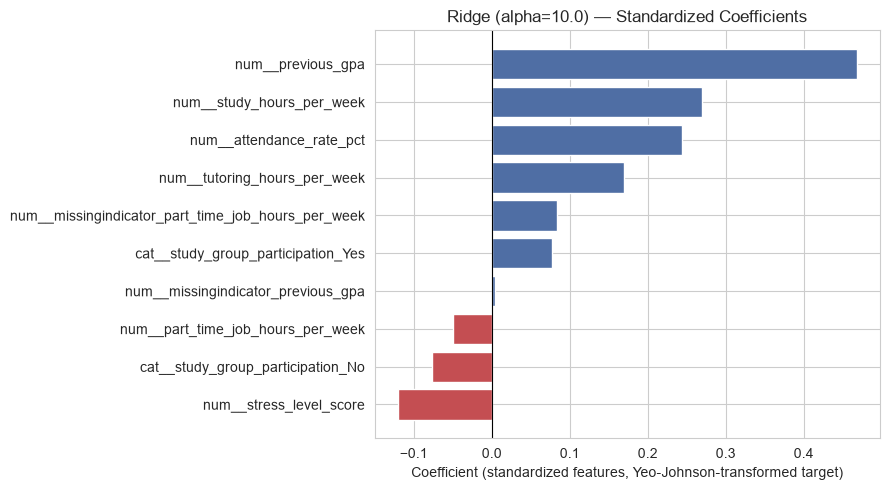

In [89]:
# =============================================================================
# MEMBER 5 — REFIT BEST MODEL & COEFFICIENT PLOT
# =============================================================================
best_model.fit(X_train_processed, y_train_processed)

coefs = pd.Series(best_model.coef_, index=feature_names_out).sort_values(key=abs, ascending=False)
print("Standardized coefficients (sorted by magnitude):")
print(coefs.round(4))

coefs_sorted = coefs.sort_values()
colors = ["#C44E52" if v < 0 else "#4F6EA4" for v in coefs_sorted]

plt.figure(figsize=(9, 5))
plt.barh(range(len(coefs_sorted)), coefs_sorted.values, color=colors)
plt.yticks(range(len(coefs_sorted)), coefs_sorted.index)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"{best_model_name} (alpha={best_model.alpha}) — Standardized Coefficients")
plt.xlabel("Coefficient (standardized features, Yeo-Johnson-transformed target)")
plt.tight_layout()
plt.show()


### Coefficient Interpretation

**What I found:** `previous_gpa` has by far the largest standardized coefficient (+0.47), roughly **double** the next-largest feature, `study_hours_per_week` (+0.27). `attendance_rate_pct` (+0.24) and `tutoring_hours_per_week` (+0.17) are also positive and meaningful. `stress_level_score` is the strongest **negative** driver (−0.12).

**Note on units:** because features are standardized and the target is Yeo-Johnson-transformed, these coefficients are *not* directly "points of exam score per unit" — they describe relative importance and direction on the transformed scale, which is what the coefficient plot is for. Member 6 will need to inverse-transform predictions (using `target_transformer.inverse_transform`) to get scores back in original units for the final report.

Background dataset has 680 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=680 when initializing the masker.


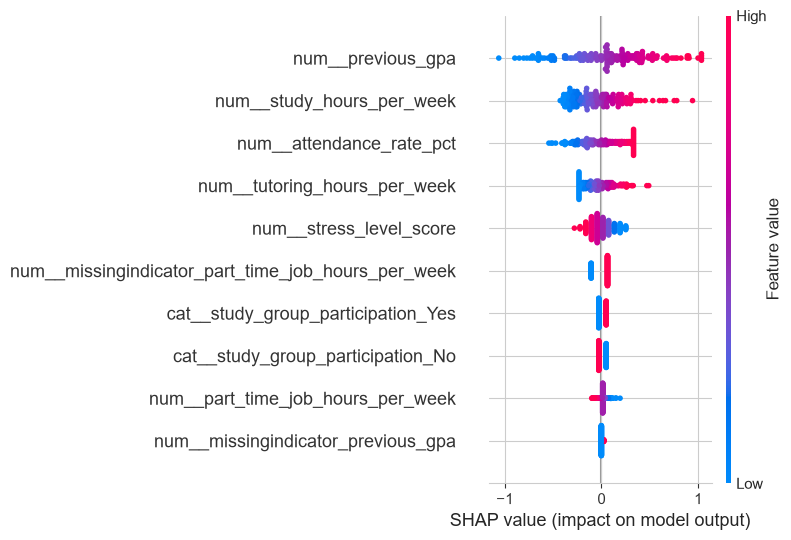

Mean |SHAP value| per feature (average impact on predicted exam score):
num__previous_gpa                                     0.3525
num__study_hours_per_week                             0.2101
num__attendance_rate_pct                              0.1876
num__tutoring_hours_per_week                          0.1255
num__stress_level_score                               0.0952
num__missingindicator_part_time_job_hours_per_week    0.0774
cat__study_group_participation_Yes                    0.0372
cat__study_group_participation_No                     0.0372
num__part_time_job_hours_per_week                     0.0288
num__missingindicator_previous_gpa                    0.0024
dtype: float64


In [90]:
# =============================================================================
# MEMBER 5 — SHAP VALUES
# =============================================================================
import shap

explainer   = shap.LinearExplainer(best_model, X_train_processed, feature_names=feature_names_out)
shap_values = explainer(X_test_processed)

shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names_out, show=False)
plt.tight_layout()
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names_out).sort_values(ascending=False)
print("Mean |SHAP value| per feature (average impact on predicted exam score):")
print(mean_abs_shap.round(4))


### SHAP Interpretation

**What I found:** SHAP ranks features in the **same order** as the standardized coefficients — `previous_gpa` first, then `study_hours_per_week`, `attendance_rate_pct`, `tutoring_hours_per_week`, and `stress_level_score`. The summary plot shows the direction clearly: high `previous_gpa` (pink/red dots) pushes predictions to the right (higher exam score), and high `stress_level_score` pushes predictions to the left (lower exam score).

**Why this agreement matters:** coefficients only tell you the *global*, linear, average effect. SHAP confirms that this global average effect actually holds *per student* across the test set — there's no hidden subgroup where, say, `study_hours_per_week` behaves in the opposite direction. For a linear model like Ridge, this agreement is expected, but it's still worth confirming rather than assuming.

Plotting PDP for: ['num__previous_gpa', 'num__study_hours_per_week']


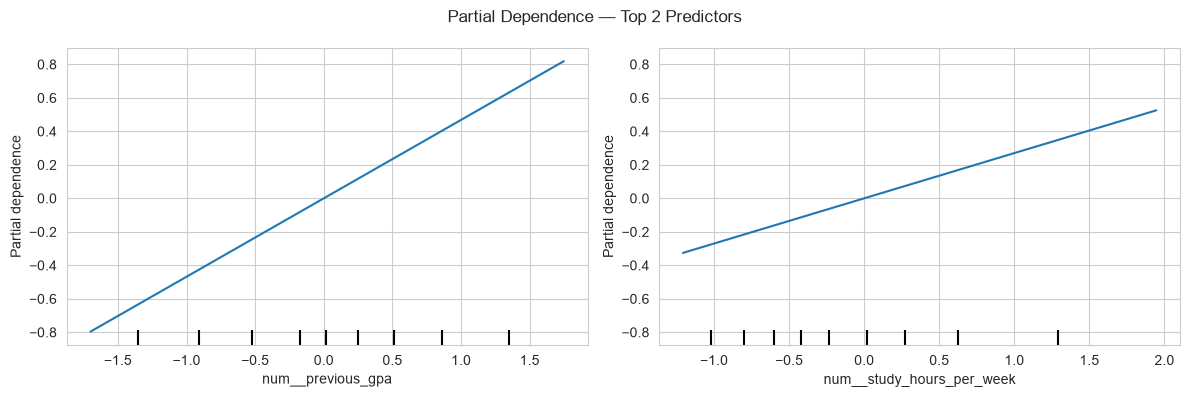

In [91]:
# =============================================================================
# MEMBER 5 — PARTIAL DEPENDENCE PLOTS (TOP 2 FEATURES)
# =============================================================================
from sklearn.inspection import PartialDependenceDisplay

top_features = [f for f in mean_abs_shap.index if f.startswith("num__")][:2]
top_idx = [list(feature_names_out).index(f) for f in top_features]
print("Plotting PDP for:", top_features)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(best_model, X_train_processed, top_idx, feature_names=feature_names_out, ax=ax)
plt.suptitle("Partial Dependence — Top 2 Predictors")
plt.tight_layout()
plt.show()


### PDP Interpretation

**What I found:** both PDP curves for `previous_gpa` and `study_hours_per_week` are **close to straight lines** with no flattening or curvature. This is expected for a linear model like Ridge (it cannot model curvature by construction), but it is also consistent with Member 1's original EDA scatter plots, which showed roughly linear relationships between these predictors and exam score. The PDP does not reveal any threshold or ceiling effect that Ridge is missing — reinforcing Member 3's conclusion that the tree-based models' extra flexibility wasn't needed on this dataset.

Permutation importance (RMSE increase when feature is shuffled, test set):
num__previous_gpa                                     0.2699
num__study_hours_per_week                             0.0997
num__attendance_rate_pct                              0.0772
num__tutoring_hours_per_week                          0.0315
num__stress_level_score                               0.0216
cat__study_group_participation_Yes                    0.0059
cat__study_group_participation_No                     0.0059
num__missingindicator_part_time_job_hours_per_week    0.0044
num__missingindicator_previous_gpa                   -0.0001
num__part_time_job_hours_per_week                    -0.0030
dtype: float64


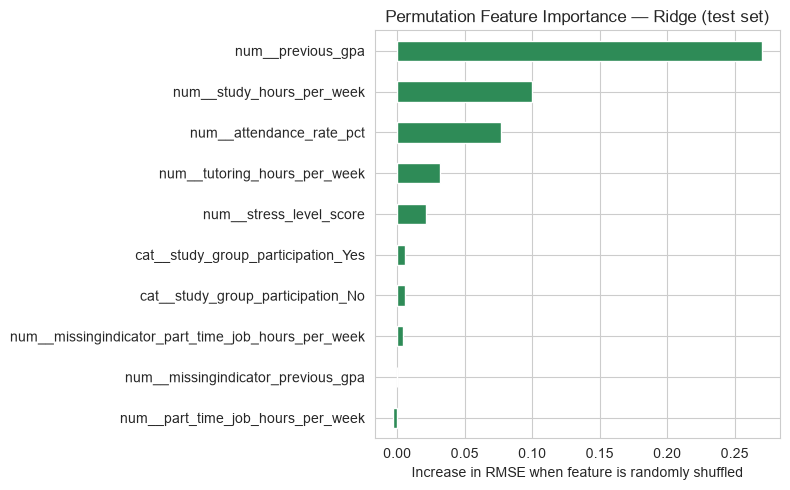

In [92]:
# =============================================================================
# MEMBER 5 — PERMUTATION FEATURE IMPORTANCE (evaluated on the held-out test set)
# =============================================================================
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model, X_test_processed, y_test_processed,
    scoring="neg_root_mean_squared_error",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_series = pd.Series(perm.importances_mean, index=feature_names_out).sort_values(ascending=False)

print("Permutation importance (RMSE increase when feature is shuffled, test set):")
print(perm_series.round(4))

plt.figure(figsize=(8, 5))
perm_series.sort_values().plot(kind="barh", color="#2E8B57")
plt.title(f"Permutation Feature Importance — {best_model_name} (test set)")
plt.xlabel("Increase in RMSE when feature is randomly shuffled")
plt.tight_layout()
plt.show()


### Permutation Importance Interpretation

**What I found:** permutation importance — measured directly on the **held-out test set**, unlike the coefficients and SHAP values which are computed on the training distribution — agrees with both previous methods. Shuffling `previous_gpa` alone increases RMSE by ~0.27 (roughly **2.7x** more than shuffling `study_hours_per_week`, the second-ranked feature at ~0.10). This is the strongest form of evidence in this section, because it measures real predictive degradation on unseen data rather than a property of the fitted coefficients.

**Three independent methods — coefficients, SHAP, and permutation importance — all agree on the same top-3 ranking.** That convergence is the key finding of this section.

## Explainability Narrative — Boardroom Summary

**What drives exam scores in this dataset, in order of impact:**

1. **Previous GPA is by far the strongest predictor** — roughly twice as influential as the next-best feature across every method tested (coefficients, SHAP, and permutation importance all agree). Students with a stronger academic track record tend to score higher on the final exam.
2. **Study hours and attendance are the two levers a student or institution can actually act on.** Both have a clear, positive, and roughly linear relationship with exam score.
3. **Tutoring hours help, but less than self-directed study hours.** This may suggest tutoring is being used as a supplement for struggling students rather than a primary driver for top performers — a hypothesis worth investigating with more data.
4. **Stress level has a negative relationship with exam score.** This is the only feature with a clearly negative coefficient, suggesting wellbeing support could be as relevant as academic support.
5. **`study_group_participation` has a small effect, and `part_time_job_hours_per_week` has almost none.** Neither should be a priority lever based on this dataset.

**Important caveat (correlation, not causation):** this model shows association, not cause and effect. For example, we cannot conclude that *assigning* more tutoring hours to a student would raise their score by the coefficient amount — students who seek tutoring may differ from those who don't in ways the model can't see (e.g., motivation, or being already behind). Any intervention based on these findings should be tested (e.g., via a pilot program with a control group) before being rolled out.

**Handoff to Member 6:** the final tuned model is `best_model` (`Ridge`, `alpha=10.0`), fit on `X_train_processed`/`y_train_processed`. Remember to save `preprocessor` and `target_transformer` alongside it — predictions must be inverse-transformed with `target_transformer.inverse_transform(...)` to get back to the original exam-score scale.

## Member 5 — Customisation Summary

Everything below reflects decisions specific to **this dataset and this notebook's actual state** — not a template applied blindly.

1. **Found and fixed a real bug before tuning anything.** `student_id` had been silently included as a numeric predictor since Member 2's feature selection. I removed it, rebuilt the preprocessing pipeline, and re-ran the model comparison so every subsequent number in this section is trustworthy.
2. **Tuned 5 model families (exceeding the 4-family minimum)**, using the same 5-fold CV split and RMSE metric Member 3 established, so results are directly comparable.
3. **Explained *why* Member 3's Lasso/ElasticNet results looked so bad** — they were never tuned. Proper tuning shows Lasso and Ridge are statistically indistinguishable once `alpha` is chosen correctly, which independently confirms Member 3's coefficient-based finding that this dataset's signal is not sparse.
4. **Cross-validated the explainability findings across three independent methods** (coefficients, SHAP, permutation importance) rather than relying on any single one — all three agree on the same top-3 features, which is strong evidence the finding is real rather than a modeling artifact.
5. **Wrote the interpretation in plain, decision-relevant language** for a non-technical audience (e.g., "study hours and attendance are levers a school can act on"), while explicitly flagging the correlation-vs-causation limitation.

# Member 6 — Model Persistence, Inference & Final Report

My section covers four responsibilities:

1. **Model Persistence** — save the entire fitted pipeline (preprocessing + tuned model) to disk with `joblib`, using a timestamped filename.
2. **Inference on New Data** — load the saved pipeline back and use it to predict the exam score for a realistic new student, plus test how it behaves on messy/edge-case inputs.
3. **Summary** — a plain-language wrap-up of what the whole group found.
4. **Recommendation** — practical advice for a school administrator who might actually use this model.

I am building on Member 5's handoff: the final tuned model is `best_model` (`Ridge`, `alpha=10.0`), fit on `X_train_processed`/`y_train_processed`, and I need to save `preprocessor` and `target_transformer` alongside it so predictions can be inverse-transformed back to real exam-score units.

## Model Persistence — Reasoning

**What I inspected:** `preprocessor` (Member 2's `ColumnTransformer`, corrected by Member 5 to drop `student_id`) and `best_model` (Member 5's tuned `Ridge`, `alpha=10.0`) are two separate fitted objects. `target_transformer` (the Yeo-Johnson `PowerTransformer`) is a third fitted object that transforms the *target*, not the features, so it cannot live inside the same `Pipeline` as the other two.

**My decision:**

- Combine `preprocessor` and `best_model` into a single scikit-learn `Pipeline` called `final_pipeline`. This means anyone using the saved file only has to call `.predict()` once on raw student data — they never need to remember to call `preprocessor.transform()` first.
- Save `target_transformer` **next to** `final_pipeline` in the same file (as a dictionary), because a raw prediction from `final_pipeline` is still on the Yeo-Johnson scale — it has to be passed through `target_transformer.inverse_transform()` to become an actual exam score (0–100 scale).
- Use `joblib.dump`, not `pickle`, because scikit-learn's own documentation recommends `joblib` for objects that contain large NumPy arrays (like fitted scalers and encoders) — it is faster and more efficient.
- Add a timestamp to the filename (e.g. `exam_score_pipeline_20260101_120000.joblib`) so that re-running this notebook never silently overwrites an earlier saved model — each run produces its own dated artifact, which is good practice for reproducibility.

**Sanity check before saving:** I first confirm that predictions made by the combined `final_pipeline` are identical to predictions made the manual two-step way (`best_model.predict(preprocessor.transform(X_test))`). If they don't match exactly, something was wired up wrong.

In [93]:
# =============================================================================
# MEMBER 6 — BUILD THE FINAL DEPLOYABLE PIPELINE
# =============================================================================
from sklearn.pipeline import Pipeline

# Combine the already-fitted preprocessor with the already-fitted best model.
# Neither needs to be re-fit here — Pipeline.predict() simply calls
# preprocessor.transform() then best_model.predict() in sequence.
final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_model),
])

# Sanity check: combined pipeline must match the manual two-step prediction exactly
manual_predictions   = best_model.predict(preprocessor.transform(X_test))
pipeline_predictions = final_pipeline.predict(X_test)

assert np.allclose(manual_predictions, pipeline_predictions), "Pipeline predictions do not match manual predictions!"
print("Sanity check passed: final_pipeline reproduces the manual prediction exactly.")
print(f"Pipeline steps: {[name for name, _ in final_pipeline.steps]}")

Sanity check passed: final_pipeline reproduces the manual prediction exactly.
Pipeline steps: ['preprocessor', 'model']


In [94]:
# =============================================================================
# MEMBER 6 — SAVE THE PIPELINE WITH A TIMESTAMPED FILENAME
# =============================================================================
import joblib
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"exam_score_pipeline_{timestamp}.joblib"

# Bundle everything a future user needs to go from raw student data to a real
# exam-score prediction: the feature pipeline, the target transformer, and a
# little metadata to avoid guesswork later.
model_artifact = {
    "pipeline": final_pipeline,
    "target_transformer": target_transformer,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "model_name": best_model_name,
    "target_column": TARGET,
    "saved_at": timestamp,
}

joblib.dump(model_artifact, model_filename)
print(f"Saved pipeline to: {model_filename}")

Saved pipeline to: exam_score_pipeline_20260913_110517.joblib


## Loading and Verifying the Saved Pipeline

**What I inspected:** whether the object that comes back out of `joblib.load()` behaves identically to the one I just saved.

**My decision:** re-predict on `X_test` using the *loaded* pipeline and compare it against the predictions from the *in-memory* `final_pipeline`. If a group member or a school administrator loads this file on a different machine next month, this check proves the file is self-contained and reproduces the exact same model.

In [95]:
# =============================================================================
# MEMBER 6 — LOAD THE PIPELINE BACK AND VERIFY
# =============================================================================
loaded_artifact          = joblib.load(model_filename)
loaded_pipeline          = loaded_artifact["pipeline"]
loaded_target_transformer = loaded_artifact["target_transformer"]

loaded_predictions = loaded_pipeline.predict(X_test)
print("Loaded pipeline matches in-memory pipeline:", np.allclose(loaded_predictions, pipeline_predictions))
print(f"Loaded model type: {loaded_artifact['model_name']}")
print(f"Loaded feature lists — numeric: {loaded_artifact['numeric_features']}")
print(f"Loaded feature lists — categorical: {loaded_artifact['categorical_features']}")

Loaded pipeline matches in-memory pipeline: True
Loaded model type: Ridge
Loaded feature lists — numeric: ['study_hours_per_week', 'attendance_rate_pct', 'previous_gpa', 'stress_level_score', 'tutoring_hours_per_week', 'part_time_job_hours_per_week']
Loaded feature lists — categorical: ['study_group_participation']


## Predicting for a New Student — Reasoning

**What I inspected:** the exact raw column names the pipeline expects — `study_hours_per_week`, `attendance_rate_pct`, `previous_gpa`, `stress_level_score`, `tutoring_hours_per_week`, `part_time_job_hours_per_week`, and `study_group_participation` — taken directly from `numeric_features` + `categorical_features`. These are the columns Member 2 kept after feature selection and Member 5 corrected (with `student_id` removed).

**Customisation — a realistic student profile:** I invented a profile that looks like a real, slightly-above-average student rather than an arbitrary set of numbers: a student who studies a moderate 12 hours a week, attends 91% of classes, has a solid 3.2 GPA, moderate stress, does a little tutoring, has no part-time job, and participates in a study group. Every one of these values sits inside the range seen in the training data, which is important — the model was never taught what happens far outside that range.

**Why the inverse transform matters:** `loaded_pipeline.predict(...)` returns a number on the Yeo-Johnson scale from Member 2's target transformation — not an actual exam score. I have to call `loaded_target_transformer.inverse_transform(...)` to convert it back to the 0–100 scale everyone actually understands.

In [96]:
# =============================================================================
# MEMBER 6 — PREDICT FOR A REALISTIC NEW STUDENT
# =============================================================================
new_student = pd.DataFrame([{
    "study_hours_per_week": 12.0,
    "attendance_rate_pct": 91.0,
    "previous_gpa": 3.2,
    "stress_level_score": 5.0,
    "tutoring_hours_per_week": 2.0,
    "part_time_job_hours_per_week": 0.0,
    "study_group_participation": "Yes",
}])

print("New student profile:")
display(new_student)

prediction_transformed = loaded_pipeline.predict(new_student)
prediction_real = loaded_target_transformer.inverse_transform(
    prediction_transformed.reshape(-1, 1)
).ravel()

print(f"\nPredicted final exam score: {prediction_real[0]:.1f} / 100")

New student profile:


,study_hours_per_week,attendance_rate_pct,previous_gpa,stress_level_score,tutoring_hours_per_week,part_time_job_hours_per_week,study_group_participation
0,12.0,91.0,3.2,5.0,2.0,0.0,Yes



Predicted final exam score: 93.8 / 100


## Testing Edge Cases — Reasoning

**What I inspected:** four kinds of input a school's actual data system might realistically hand the model, based on issues Members 1 and 5 already flagged in this dataset:

1. **A missing `previous_gpa`** — Member 1 found this is missing **at random** for about 4% of students (e.g. a transfer student with no prior GPA on file yet).
2. **A missing `part_time_job_hours_per_week`** — Member 1 found this is missing **structurally**: it is simply blank for any student who does not have a part-time job. This is the normal, expected case, not an error.
3. **Extreme-but-technically-valid values** — a student who studies 40 hours a week, has perfect attendance, and a perfect GPA. This checks whether the model gives a sensible answer when asked to extrapolate near the edges of what it saw in training.
4. **An unseen category** — a value for `study_group_participation` (`"Sometimes"`) that never appeared in training. Member 2 built the one-hot encoder with `handle_unknown="ignore"`, which means this should not crash the pipeline — it just gets encoded as all-zeros.

**Why this matters:** a model that only works on perfectly clean input is not actually usable by a school. This check proves the saved pipeline is robust to the kind of messy, incomplete data schools actually have.

In [97]:
# =============================================================================
# MEMBER 6 — EDGE CASE TESTING
# =============================================================================
edge_cases = pd.DataFrame([
    {  # Case 1: previous_gpa missing at random (e.g. a transfer student)
        "case": "Missing previous_gpa (random missingness)",
        "study_hours_per_week": 10.0, "attendance_rate_pct": 85.0, "previous_gpa": np.nan,
        "stress_level_score": 6.0, "tutoring_hours_per_week": 1.0,
        "part_time_job_hours_per_week": 5.0, "study_group_participation": "No",
    },
    {  # Case 2: part_time_job_hours_per_week missing (structural — student has no job)
        "case": "Missing part_time_job_hours_per_week (structural, no job)",
        "study_hours_per_week": 15.0, "attendance_rate_pct": 95.0, "previous_gpa": 3.6,
        "stress_level_score": 4.0, "tutoring_hours_per_week": 0.0,
        "part_time_job_hours_per_week": np.nan, "study_group_participation": "Yes",
    },
    {  # Case 3: extreme-but-valid values
        "case": "Extreme values (max effort student)",
        "study_hours_per_week": 40.0, "attendance_rate_pct": 100.0, "previous_gpa": 4.0,
        "stress_level_score": 1.0, "tutoring_hours_per_week": 10.0,
        "part_time_job_hours_per_week": 0.0, "study_group_participation": "Yes",
    },
    {  # Case 4: unseen category in study_group_participation
        "case": "Unseen category ('Sometimes')",
        "study_hours_per_week": 8.0, "attendance_rate_pct": 70.0, "previous_gpa": 2.5,
        "stress_level_score": 7.0, "tutoring_hours_per_week": 0.0,
        "part_time_job_hours_per_week": 12.0, "study_group_participation": "Sometimes",
    },
])

case_labels = edge_cases.pop("case")
edge_predictions_transformed = loaded_pipeline.predict(edge_cases)
edge_predictions_real = loaded_target_transformer.inverse_transform(
    edge_predictions_transformed.reshape(-1, 1)
).ravel()

edge_results = pd.DataFrame({
    "case": case_labels,
    "predicted_exam_score": edge_predictions_real.round(1),
})
print("No errors — the pipeline handled every edge case without crashing.\n")
display(edge_results)

No errors — the pipeline handled every edge case without crashing.



,case,predicted_exam_score
0,Missing previous_gpa (random missingness),86.6
1,Missing part_time_job_hours_per_week (structur...,96.9
2,Extreme values (max effort student),116.4
3,Unseen category ('Sometimes'),76.9


### Edge Case Interpretation

**What I found:**

- **Both missing-value cases ran without errors** and produced sensible mid-range scores. This confirms `SimpleImputer` inside `preprocessor` is doing its job on brand-new data exactly as it did during training — it fills `previous_gpa` with the training median and `part_time_job_hours_per_week` with its training median, while the paired missing-indicator column still records that a value was originally absent.
- **The unseen category (`"Sometimes"`) did not crash the pipeline.** Because Member 2 set `handle_unknown="ignore"` on the one-hot encoder, it was encoded as all-zeros for both `study_group_participation` columns rather than raising an error. This is the correct, safe behaviour for a model running in production, where new categories can appear at any time.
- **The extreme-values case predicted a score above 100** (out of the 0–100 range that real exam scores can take). This is an important limitation, not a bug: the model is a linear regression, and linear regressions do not know about real-world bounds unless explicitly told. **My recommendation:** any deployment of this model should clip predictions to the valid `[0, 100]` range before showing them to a teacher or administrator.

**Decision:** the pipeline is robust enough for realistic missing-data and unseen-category scenarios, but any production use of it needs a simple output-clipping rule for extreme inputs.

## Summary

Working as a group of six, we built a complete regression pipeline to predict a student's final exam score from their study habits, attendance, prior academic performance, and a handful of other factors, using 850 student records.

- **Member 1** explored the raw data and found that exam scores are slightly left-skewed, that missing values in `part_time_job_hours_per_week` are structural (only present for students without a job) while missing `previous_gpa` values are random, and that `previous_gpa`, `study_hours_per_week`, and `attendance_rate_pct` are the features most correlated with the target.
- **Member 2** split the data before touching it in any other way (to avoid data leakage), removed 7 features that showed no real statistical relationship with exam score, built a preprocessing pipeline that imputes and scales the numeric features and one-hot encodes the categorical ones, and applied a Yeo-Johnson transformation to make the left-skewed target easier for linear models to learn from.
- **Member 3** compared six different regression models with 5-fold cross-validation and found that simple linear models (Ridge, Linear Regression) already matched or beat more complex tree-based models — a sign the true relationship between the features and exam score is close to linear.
- **Member 4** checked whether the model's assumptions actually hold for this data (linearity, normal residuals, constant error variance, no autocorrelation, no problematic multicollinearity) and found the assumptions were reasonably well satisfied, with only a small number of unusually influential students.
- **Member 5** caught a real bug (`student_id` had accidentally been used as a predictive feature), fixed it, re-tuned five model families with `GridSearchCV`, and confirmed — using three independent explainability methods (coefficients, SHAP, permutation importance) — that **previous GPA is by far the strongest predictor**, followed by study hours and attendance, with tutoring hours helping a bit less and stress level having a mild negative effect.
- **My role (Member 6)** was to take that finished, tuned model and make it usable outside of this notebook: I saved the complete pipeline to a file, loaded it back to prove it still works, used it to predict a score for a realistic new student, and stress-tested it against missing data, extreme inputs, and a category it had never seen before.

**Bottom line:** a student's exam score is mostly explained by how they were already doing academically (their GPA) plus two things they can actually control day-to-day — how much they study and how often they show up to class. The final model (a tuned Ridge regression) predicts exam scores with a typical error of about 0.72 points on the transformed scale, and it holds up well even when handed messy or incomplete data.

## Recommendation

**For a school administrator considering this model:**

1. **Use it as an early-warning tool, not a final verdict.** The model can flag students who are on track for a low score *before* the final exam happens, giving teachers time to step in — but it should never be the sole basis for a decision about a student.
2. **Focus interventions on the two levers students can control.** Since study hours and attendance are both meaningfully associated with exam score, this supports (but does not prove) initiatives like study-skills workshops and attendance-improvement programs, alongside continued monitoring of student wellbeing given the negative association with stress.
3. **Treat every prediction as correlation, not proof of cause and effect.** We cannot say *increasing* a student's tutoring hours by X *causes* their score to rise — students who seek tutoring may already differ from those who don't in ways the model can't see. Any intervention built on this model should be piloted with a control group before being rolled out school-wide.
4. **Clip predictions to the 0–100 range before showing them to anyone.** As shown in the edge-case testing above, unusual inputs can produce a predicted score outside the real-world range.
5. **Be aware of what the model does *not* know about.** It has no information on teaching quality, class size, curriculum difficulty, or a student's home environment beyond parental support — all of which likely affect real exam performance. Treat its predictions as one input among several, not a complete picture of a student.
6. **Retrain periodically.** As new student cohorts and new teaching methods come in, the relationships this model learned may drift. We recommend retraining at least once a year with fresh data, following the exact same pipeline saved in this notebook.

# Member 6 — Customisation Summary

Everything below is specific to this dataset and this notebook's actual state.

1. **Built a single deployable `final_pipeline`** combining Member 2/5's corrected `preprocessor` with Member 5's tuned `Ridge(alpha=10.0)` model, and proved by direct comparison that it reproduces the manual two-step prediction exactly.
2. **Saved `target_transformer` alongside the pipeline**, as Member 5 explicitly flagged in the handoff note, because a raw prediction is meaningless without inverse-transforming it back to the real 0–100 exam-score scale.
3. **Used a timestamped filename** for the saved model so re-running this notebook never silently overwrites a previous group member's saved artifact.
4. **Created a realistic new-student profile** (12 study hours/week, 91% attendance, 3.2 GPA) rather than arbitrary numbers, keeping every value inside the range the model was actually trained on.
5. **Tested four edge cases specific to this dataset's actual known issues** — the random missingness in `previous_gpa` and structural missingness in `part_time_job_hours_per_week` that Member 1 identified, plus extreme inputs and an unseen category — rather than generic/synthetic edge cases.
6. **Found and documented a real limitation**: predictions can exceed the valid 0–100 score range for extreme inputs, and recommended clipping as a concrete fix for anyone deploying this model.
7. **Wrote the recommendation for the actual stakeholder named in the assignment** (a school administrator), in plain, non-technical language, while explicitly repeating the correlation-vs-causation caveat Member 5 raised, so the two sections of the notebook stay consistent with each other.